# Customer-Level Feature Engineering

## Project: Customer Intelligence Platform

### Objective
Prepare a customer-level analytical dataset from the Olist e-commerce data to support predictive modelling and customer behaviour analysis.

### Key Tasks
1. Define the prediction objective and observation window.
2. Identify eligible customers and establish the dataset grain.
3. Engineer customer purchasing and behavioural features.
4. Define the repeat-purchase target using future purchasing activity.
5. Validate feature quality, missing values, and data leakage.
6. Prepare the final modelling dataset.

### Important Principle
Only information available at the prediction date should be used to construct predictive features.

## Prediction Problem Definition

### Business Question
Can we predict whether a customer will make another delivered purchase within 60 days of their first delivered purchase?

### Prediction Point
The purchase timestamp of the customer's first delivered order.

### Target Variable
- 1: Customer makes another delivered purchase within 60 days.
- 0: Customer does not make another delivered purchase within 60 days.

### Modelling Dataset
One row per eligible customer.

### Eligibility
Customers must have enough observable data to complete the 60-day follow-up period.

### Data Leakage Prevention
Predictive features must be based only on information available at the first purchase timestamp. Future purchases and their outcomes must not be included as predictive features.

In [5]:
from pathlib import Path
import pandas as pd
import numpy as np

# Set the path to our project datasets
data_path = Path.cwd().parent / "data"

print("Libraries imported successfully!")
print("Dataset folder:", data_path)
print("Folder exists:", data_path.exists())

Libraries imported successfully!
Dataset folder: c:\Users\oades\Downloads\Downloads\customer-intelligence-platform\data
Folder exists: True


In [6]:
# Load customer and order datasets
customers = pd.read_csv(data_path / "olist_customers_dataset.csv")
orders = pd.read_csv(data_path / "olist_orders_dataset.csv")

# Check the number of rows and columns
print("Customers dataset:", customers.shape)
print("Orders dataset:", orders.shape)

Customers dataset: (99441, 5)
Orders dataset: (99441, 8)


In [7]:
# Examine the columns in both datasets

print("CUSTOMERS DATASET COLUMNS")
print(customers.columns.tolist())

print("\nORDERS DATASET COLUMNS")
print(orders.columns.tolist())

CUSTOMERS DATASET COLUMNS
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

ORDERS DATASET COLUMNS
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']


In [8]:
# Merge orders with customer information

customer_orders = orders.merge(
    customers,
    on="customer_id",
    how="left",
    validate="one_to_one"
)

# Check the merged dataset
print("Merged dataset shape:", customer_orders.shape)

print(
    "Missing customer identities:",
    customer_orders["customer_unique_id"].isna().sum()
)

print(
    "Unique customers:",
    customer_orders["customer_unique_id"].nunique()
)

Merged dataset shape: (99441, 12)
Missing customer identities: 0
Unique customers: 96096


In [9]:
# Convert order purchase timestamps to datetime

customer_orders["order_purchase_timestamp"] = pd.to_datetime(
    customer_orders["order_purchase_timestamp"],
    errors="coerce"
)

# Check the conversion
print(
    "Purchase date data type:",
    customer_orders["order_purchase_timestamp"].dtype
)

print(
    "Missing purchase dates:",
    customer_orders["order_purchase_timestamp"].isna().sum()
)

print(
    "Earliest purchase:",
    customer_orders["order_purchase_timestamp"].min()
)

print(
    "Latest purchase:",
    customer_orders["order_purchase_timestamp"].max()
)

Purchase date data type: datetime64[us]
Missing purchase dates: 0
Earliest purchase: 2016-09-04 21:15:19
Latest purchase: 2018-10-17 17:30:18


In [10]:
# Keep only successfully delivered orders

delivered_orders = customer_orders[
    customer_orders["order_status"] == "delivered"
].copy()

# Validate the delivered-order population

print("Delivered orders:", len(delivered_orders))

print(
    "Unique delivered customers:",
    delivered_orders["customer_unique_id"].nunique()
)

print(
    "Missing purchase dates:",
    delivered_orders["order_purchase_timestamp"].isna().sum()
)

Delivered orders: 96478
Unique delivered customers: 93358
Missing purchase dates: 0


In [11]:
# Arrange each customer's delivered orders chronologically
delivered_orders = delivered_orders.sort_values(
    by=[
        "customer_unique_id",
        "order_purchase_timestamp",
        "order_id"
    ]
).copy()

# Assign a purchase number to each order
delivered_orders["purchase_number"] = (
    delivered_orders.groupby("customer_unique_id").cumcount() + 1
)

# Select the first delivered purchase for each customer
first_purchases = delivered_orders[
    delivered_orders["purchase_number"] == 1
].copy()

# Validate the results
print("First-purchase records:", len(first_purchases))
print("Unique customers:", first_purchases["customer_unique_id"].nunique())
print("Duplicate customers:", first_purchases["customer_unique_id"].duplicated().sum())

First-purchase records: 93358
Unique customers: 93358
Duplicate customers: 0


In [12]:
# Examine the first purchase dates

print(
    "Earliest first purchase:",
    first_purchases["order_purchase_timestamp"].min()
)

print(
    "Latest first purchase:",
    first_purchases["order_purchase_timestamp"].max()
)

print(
    "Missing first purchase dates:",
    first_purchases["order_purchase_timestamp"].isna().sum()
)

Earliest first purchase: 2016-09-15 12:16:38
Latest first purchase: 2018-08-29 15:00:37
Missing first purchase dates: 0


In [13]:
# Define our observation cutoff and prediction window

observation_cutoff = pd.Timestamp("2018-08-31 23:59:59")
prediction_window = pd.Timedelta(days=60)

# Calculate the latest eligible first-purchase date
latest_eligible_date = observation_cutoff - prediction_window

# Identify customers with a complete 60-day follow-up window
eligible_first_purchases = first_purchases[
    first_purchases["order_purchase_timestamp"] <= latest_eligible_date
].copy()

# Validate eligibility
print("Observation cutoff:", observation_cutoff)
print("Latest eligible first-purchase date:", latest_eligible_date)
print("Eligible customers:", len(eligible_first_purchases))
print("Ineligible customers:", len(first_purchases) - len(eligible_first_purchases))

Observation cutoff: 2018-08-31 23:59:59
Latest eligible first-purchase date: 2018-07-02 23:59:59
Eligible customers: 81608
Ineligible customers: 11750


In [14]:
# Identify each customer's second delivered purchase

second_purchases = delivered_orders[
    delivered_orders["purchase_number"] == 2
][
    ["customer_unique_id", "order_purchase_timestamp"]
].copy()

# Rename the timestamp for clarity
second_purchases = second_purchases.rename(
    columns={
        "order_purchase_timestamp": "second_purchase_date"
    }
)

# Validate the second-purchase records
print("Second-purchase records:", len(second_purchases))

print(
    "Unique customers with a second purchase:",
    second_purchases["customer_unique_id"].nunique()
)

print(
    "Duplicate customer records:",
    second_purchases["customer_unique_id"].duplicated().sum()
)

Second-purchase records: 2801
Unique customers with a second purchase: 2801
Duplicate customer records: 0


In [15]:
# Connect eligible first purchases with second purchases

customer_returns = eligible_first_purchases.merge(
    second_purchases,
    on="customer_unique_id",
    how="left",
    validate="one_to_one"
)

# Validate the merged dataset

print("Customer records:", len(customer_returns))

print(
    "Unique customers:",
    customer_returns["customer_unique_id"].nunique()
)

print(
    "Customers with a recorded second purchase:",
    customer_returns["second_purchase_date"].notna().sum()
)

print(
    "Customers without a recorded second purchase:",
    customer_returns["second_purchase_date"].isna().sum()
)

print(
    "Duplicate customers:",
    customer_returns["customer_unique_id"].duplicated().sum()
)

Customer records: 81608
Unique customers: 81608
Customers with a recorded second purchase: 2682
Customers without a recorded second purchase: 78926
Duplicate customers: 0


In [16]:
# Calculate the time between first and second delivered purchases

customer_returns["days_to_second_purchase"] = (
    customer_returns["second_purchase_date"]
    - customer_returns["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Validate the purchase intervals

print(
    "Customers with a calculated interval:",
    customer_returns["days_to_second_purchase"].notna().sum()
)

print(
    "Negative intervals:",
    (customer_returns["days_to_second_purchase"] < 0).sum()
)

print(
    "Customers returning within 60 days:",
    customer_returns["days_to_second_purchase"].between(
        0, 60, inclusive="both"
    ).sum()
)

Customers with a calculated interval: 2682
Negative intervals: 0
Customers returning within 60 days: 1588


In [17]:
# Create a preliminary 60-day repeat-purchase target

customer_returns["repeat_purchase_60d"] = (
    customer_returns["days_to_second_purchase"]
    .between(0, 60, inclusive="both")
    .astype(int)
)

# Check the target distribution
print("Target distribution:")
print(customer_returns["repeat_purchase_60d"].value_counts())

print(
    "\nRepeat-purchase rate:",
    round(customer_returns["repeat_purchase_60d"].mean() * 100, 2),
    "%"
)

print(
    "\nMissing target values:",
    customer_returns["repeat_purchase_60d"].isna().sum()
)

Target distribution:
repeat_purchase_60d
0    80020
1     1588
Name: count, dtype: int64

Repeat-purchase rate: 1.95 %

Missing target values: 0


In [18]:
# Find the earliest recorded order date for each customer
earliest_order_dates = (
    customer_orders
    .groupby("customer_unique_id")["order_purchase_timestamp"]
    .min()
)

# Compare with each customer's first delivered purchase date
first_purchase_audit = first_purchases[
    ["customer_unique_id", "order_purchase_timestamp"]
].copy()

first_purchase_audit["earliest_order_date"] = (
    first_purchase_audit["customer_unique_id"]
    .map(earliest_order_dates)
)

first_purchase_audit["had_earlier_order"] = (
    first_purchase_audit["earliest_order_date"]
    < first_purchase_audit["order_purchase_timestamp"]
)

print("Customers audited:", len(first_purchase_audit))

print(
    "Customers with an earlier recorded order:",
    first_purchase_audit["had_earlier_order"].sum()
)

print(
    "Customers whose first delivered purchase matches their earliest order date:",
    (~first_purchase_audit["had_earlier_order"]).sum()
)

Customers audited: 93358
Customers with an earlier recorded order: 92
Customers whose first delivered purchase matches their earliest order date: 93266


In [19]:
# Identify customers with orders before their first delivered purchase

earlier_order_customers = first_purchase_audit.loc[
    first_purchase_audit["had_earlier_order"],
    "customer_unique_id"
]

# Retrieve their earliest recorded order dates and statuses
earlier_orders = customer_orders[
    customer_orders["customer_unique_id"].isin(earlier_order_customers)
].copy()

earlier_orders = earlier_orders[
    earlier_orders["order_purchase_timestamp"]
    == earlier_orders.groupby("customer_unique_id")[
        "order_purchase_timestamp"
    ].transform("min")
]

# Examine the status of these earlier orders
print("Customers identified:", earlier_order_customers.nunique())

print("\nEarliest recorded order statuses:")
print(earlier_orders["order_status"].value_counts())

print(
    "\nCustomers represented:",
    earlier_orders["customer_unique_id"].nunique()
)

Customers identified: 92

Earliest recorded order statuses:
order_status
shipped        32
canceled       25
unavailable    17
invoiced        9
processing      8
created         1
Name: count, dtype: int64

Customers represented: 92


In [20]:
# Identify the first recorded order for every customer
# Include all order statuses, not just delivered orders

all_orders_sorted = customer_orders.sort_values(
    by=[
        "customer_unique_id",
        "order_purchase_timestamp",
        "order_id"
    ]
).copy()

# Number orders chronologically
all_orders_sorted["order_number"] = (
    all_orders_sorted
    .groupby("customer_unique_id")
    .cumcount() + 1
)

# Select the first recorded order per customer
first_recorded_orders = all_orders_sorted[
    all_orders_sorted["order_number"] == 1
].copy()

# Validate the dataset
print("First recorded orders:", len(first_recorded_orders))

print(
    "Unique customers:",
    first_recorded_orders["customer_unique_id"].nunique()
)

print(
    "Duplicate customers:",
    first_recorded_orders["customer_unique_id"].duplicated().sum()
)

print("\nFirst recorded order statuses:")
print(first_recorded_orders["order_status"].value_counts())

First recorded orders: 96096
Unique customers: 96096
Duplicate customers: 0

First recorded order statuses:
order_status
delivered      93256
shipped         1078
unavailable      589
canceled         564
invoiced         308
processing       294
created            5
approved           2
Name: count, dtype: int64


In [21]:
# Identify eligible customers using their first recorded order date

eligible_first_orders = first_recorded_orders[
    first_recorded_orders["order_purchase_timestamp"]
    <= latest_eligible_date
].copy()

# Validate the new modelling population

print("All customers:", len(first_recorded_orders))

print("Eligible customers:", len(eligible_first_orders))

print(
    "Ineligible customers:",
    len(first_recorded_orders) - len(eligible_first_orders)
)

print(
    "Duplicate eligible customers:",
    eligible_first_orders["customer_unique_id"].duplicated().sum()
)

print(
    "Missing first-order dates:",
    eligible_first_orders["order_purchase_timestamp"].isna().sum()
)

All customers: 96096
Eligible customers: 84094
Ineligible customers: 12002
Duplicate eligible customers: 0
Missing first-order dates: 0


In [22]:
# Identify delivered orders after each customer's first recorded order

subsequent_delivered_orders = all_orders_sorted[
    (all_orders_sorted["order_number"] > 1)
    & (all_orders_sorted["order_status"] == "delivered")
].copy()

# Keep the earliest subsequent delivered order for each customer
first_subsequent_delivered = (
    subsequent_delivered_orders
    .sort_values(
        ["customer_unique_id", "order_purchase_timestamp", "order_id"]
    )
    .drop_duplicates(subset="customer_unique_id", keep="first")
    [
        ["customer_unique_id", "order_purchase_timestamp"]
    ]
    .rename(
        columns={
            "order_purchase_timestamp": "next_delivered_purchase_date"
        }
    )
)

# Validate the results
print(
    "Customers with a subsequent delivered order:",
    len(first_subsequent_delivered)
)

print(
    "Unique customers:",
    first_subsequent_delivered["customer_unique_id"].nunique()
)

print(
    "Duplicate customers:",
    first_subsequent_delivered["customer_unique_id"].duplicated().sum()
)

Customers with a subsequent delivered order: 2895
Unique customers: 2895
Duplicate customers: 0


In [23]:
# Connect eligible first orders to subsequent delivered purchases

modelling_customers = eligible_first_orders.merge(
    first_subsequent_delivered,
    on="customer_unique_id",
    how="left",
    validate="one_to_one"
)

# Validate the merged dataset

print("Customer records:", len(modelling_customers))

print(
    "Unique customers:",
    modelling_customers["customer_unique_id"].nunique()
)

print(
    "Customers with a subsequent delivered order:",
    modelling_customers["next_delivered_purchase_date"].notna().sum()
)

print(
    "Customers without a subsequent delivered order:",
    modelling_customers["next_delivered_purchase_date"].isna().sum()
)

print(
    "Duplicate customers:",
    modelling_customers["customer_unique_id"].duplicated().sum()
)

Customer records: 84094
Unique customers: 84094
Customers with a subsequent delivered order: 2775
Customers without a subsequent delivered order: 81319
Duplicate customers: 0


In [24]:
# Calculate days from first recorded order
# to the first subsequent delivered order

modelling_customers["days_to_next_delivered_purchase"] = (
    modelling_customers["next_delivered_purchase_date"]
    - modelling_customers["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Validate the calculated intervals
print(
    "Customers with a calculated interval:",
    modelling_customers["days_to_next_delivered_purchase"].notna().sum()
)

print(
    "Negative intervals:",
    (modelling_customers["days_to_next_delivered_purchase"] < 0).sum()
)

print(
    "Customers returning within 60 days:",
    modelling_customers["days_to_next_delivered_purchase"]
    .between(0, 60, inclusive="both").sum()
)

print(
    "Customers returning after 60 days:",
    (modelling_customers["days_to_next_delivered_purchase"] > 60).sum()
)

Customers with a calculated interval: 2775
Negative intervals: 0
Customers returning within 60 days: 1652
Customers returning after 60 days: 1123


In [25]:
# Check whether subsequent orders were delivered by our cutoff

delivery_audit = subsequent_delivered_orders[
    [
        "customer_unique_id",
        "order_purchase_timestamp",
        "order_delivered_customer_date"
    ]
].copy()

# Convert actual delivery dates to datetime
delivery_audit["order_delivered_customer_date"] = pd.to_datetime(
    delivery_audit["order_delivered_customer_date"],
    errors="coerce"
)

# Keep the first subsequent delivered order for each customer
delivery_audit = (
    delivery_audit
    .sort_values(
        ["customer_unique_id", "order_purchase_timestamp"]
    )
    .drop_duplicates("customer_unique_id")
)

# Restrict the audit to our eligible customers
delivery_audit = delivery_audit[
    delivery_audit["customer_unique_id"].isin(
        eligible_first_orders["customer_unique_id"]
    )
]

print("Subsequent delivered orders audited:", len(delivery_audit))

print(
    "Missing actual delivery dates:",
    delivery_audit["order_delivered_customer_date"].isna().sum()
)

print(
    "Delivered after observation cutoff:",
    (
        delivery_audit["order_delivered_customer_date"]
        > observation_cutoff
    ).sum()
)

Subsequent delivered orders audited: 2775
Missing actual delivery dates: 0
Delivered after observation cutoff: 1


In [26]:
# Identify subsequent orders delivered after our observation cutoff

late_deliveries = delivery_audit[
    delivery_audit["order_delivered_customer_date"] > observation_cutoff
].copy()

# Compare each late delivery with the customer's first order
late_delivery_check = late_deliveries.merge(
    eligible_first_orders[
        ["customer_unique_id", "order_purchase_timestamp"]
    ].rename(
        columns={
            "order_purchase_timestamp": "first_order_date"
        }
    ),
    on="customer_unique_id",
    how="left",
    validate="one_to_one"
)

# Calculate the return interval
late_delivery_check["days_to_return"] = (
    late_delivery_check["order_purchase_timestamp"]
    - late_delivery_check["first_order_date"]
).dt.total_seconds() / 86400

# Display the relevant dates and return interval
print(
    late_delivery_check[
        [
            "first_order_date",
            "order_purchase_timestamp",
            "order_delivered_customer_date",
            "days_to_return"
        ]
    ].to_string(index=False)
)

   first_order_date order_purchase_timestamp order_delivered_customer_date  days_to_return
2017-10-30 16:10:26      2018-07-24 08:10:01           2018-09-01 01:22:46      266.666377


In [27]:
# Identify customers with a subsequent purchase within 60 days
returning_60d = modelling_customers[
    modelling_customers["days_to_next_delivered_purchase"].between(
        0, 60, inclusive="both"
    )
].copy()

# Connect those customers to their audited delivery dates
returning_60d_audit = returning_60d[
    ["customer_unique_id"]
].merge(
    delivery_audit[
        ["customer_unique_id", "order_delivered_customer_date"]
    ],
    on="customer_unique_id",
    how="left",
    validate="one_to_one"
)

# Validate the positive cases
print("Preliminary 60-day returners:", len(returning_60d_audit))

print(
    "Missing delivery dates:",
    returning_60d_audit["order_delivered_customer_date"].isna().sum()
)

print(
    "Delivered by observation cutoff:",
    (
        returning_60d_audit["order_delivered_customer_date"]
        <= observation_cutoff
    ).sum()
)

print(
    "Delivered after observation cutoff:",
    (
        returning_60d_audit["order_delivered_customer_date"]
        > observation_cutoff
    ).sum()
)

Preliminary 60-day returners: 1652
Missing delivery dates: 0
Delivered by observation cutoff: 1652
Delivered after observation cutoff: 0


In [28]:
# Connect all subsequent delivered orders to eligible first-order dates

all_return_candidates = subsequent_delivered_orders[
    [
        "customer_unique_id",
        "order_purchase_timestamp",
        "order_delivered_customer_date"
    ]
].merge(
    eligible_first_orders[
        ["customer_unique_id", "order_purchase_timestamp"]
    ].rename(
        columns={
            "order_purchase_timestamp": "first_order_date"
        }
    ),
    on="customer_unique_id",
    how="inner",
    validate="many_to_one"
)

# Calculate the time between the first and subsequent orders
all_return_candidates["days_since_first_order"] = (
    all_return_candidates["order_purchase_timestamp"]
    - all_return_candidates["first_order_date"]
).dt.total_seconds() / 86400

# Validate all qualifying return purchases
print(
    "All subsequent delivered orders:",
    len(all_return_candidates)
)

print(
    "Orders purchased within 60 days:",
    all_return_candidates["days_since_first_order"]
    .between(0, 60, inclusive="both").sum()
)

print(
    "Unique customers returning within 60 days:",
    all_return_candidates.loc[
        all_return_candidates["days_since_first_order"]
        .between(0, 60, inclusive="both"),
        "customer_unique_id"
    ].nunique()
)

All subsequent delivered orders: 3099
Orders purchased within 60 days: 1749
Unique customers returning within 60 days: 1652


In [29]:
# Select all subsequent orders purchased within 60 days

qualifying_orders = all_return_candidates[
    all_return_candidates["days_since_first_order"].between(
        0, 60, inclusive="both"
    )
].copy()

# Convert delivery dates to datetime
qualifying_orders["order_delivered_customer_date"] = pd.to_datetime(
    qualifying_orders["order_delivered_customer_date"],
    errors="coerce"
)

# Check delivery outcomes
print("Qualifying orders:", len(qualifying_orders))

print(
    "Unique qualifying customers:",
    qualifying_orders["customer_unique_id"].nunique()
)

print(
    "Missing delivery dates:",
    qualifying_orders["order_delivered_customer_date"].isna().sum()
)

print(
    "Orders delivered by cutoff:",
    (
        qualifying_orders["order_delivered_customer_date"]
        <= observation_cutoff
    ).sum()
)

print(
    "Orders delivered after cutoff:",
    (
        qualifying_orders["order_delivered_customer_date"]
        > observation_cutoff
    ).sum()
)

Qualifying orders: 1749
Unique qualifying customers: 1652
Missing delivery dates: 0
Orders delivered by cutoff: 1749
Orders delivered after cutoff: 0


In [30]:
# Identify customers with a qualifying 60-day repeat purchase

qualifying_customer_ids = qualifying_orders.loc[
    qualifying_orders["order_delivered_customer_date"] <= observation_cutoff,
    "customer_unique_id"
].unique()

# Create our revised target variable
modelling_customers["repeat_purchase_60d"] = (
    modelling_customers["customer_unique_id"]
    .isin(qualifying_customer_ids)
    .astype(int)
)

# Validate the target distribution
print("Target distribution:")
print(modelling_customers["repeat_purchase_60d"].value_counts())

print(
    "\nRepeat-purchase rate:",
    round(modelling_customers["repeat_purchase_60d"].mean() * 100, 2),
    "%"
)

print(
    "\nMissing target values:",
    modelling_customers["repeat_purchase_60d"].isna().sum()
)

Target distribution:
repeat_purchase_60d
0    82442
1     1652
Name: count, dtype: int64

Repeat-purchase rate: 1.96 %

Missing target values: 0


In [31]:
# Measure delivery time for successfully delivered orders

delivery_times = delivered_orders[
    ["order_purchase_timestamp", "order_delivered_customer_date"]
].copy()

delivery_times["order_delivered_customer_date"] = pd.to_datetime(
    delivery_times["order_delivered_customer_date"],
    errors="coerce"
)

# Calculate the number of days from purchase to delivery
delivery_times["delivery_days"] = (
    delivery_times["order_delivered_customer_date"]
    - delivery_times["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Keep valid delivery intervals
valid_delivery_times = delivery_times[
    delivery_times["delivery_days"].notna()
    & (delivery_times["delivery_days"] >= 0)
]

print("Valid delivery intervals:", len(valid_delivery_times))

print("\nDelivery time distribution (days):")
print(
    valid_delivery_times["delivery_days"].quantile(
        [0.50, 0.90, 0.95, 0.99]
    ).round(2)
)

print(
    "\nLongest recorded delivery time:",
    round(valid_delivery_times["delivery_days"].max(), 2),
    "days"
)

Valid delivery intervals: 96470

Delivery time distribution (days):
0.50    10.22
0.90    23.10
0.95    29.27
0.99    46.05
Name: delivery_days, dtype: float64

Longest recorded delivery time: 209.63 days


In [32]:
# Assess eligibility with an additional 30-day delivery buffer

delivery_buffer = pd.Timedelta(days=30)

latest_buffered_first_order = (
    observation_cutoff
    - prediction_window
    - delivery_buffer
)

# Identify customers with 60 days for purchases
# plus 30 additional days for delivery confirmation

buffered_eligible_customers = first_recorded_orders[
    first_recorded_orders["order_purchase_timestamp"]
    <= latest_buffered_first_order
].copy()

print(
    "Latest eligible first-order date with buffer:",
    latest_buffered_first_order
)

print(
    "Customers eligible with 60-day window only:",
    len(eligible_first_orders)
)

print(
    "Customers eligible with 30-day delivery buffer:",
    len(buffered_eligible_customers)
)

print(
    "Customers excluded by adding the buffer:",
    len(eligible_first_orders) - len(buffered_eligible_customers)
)

Latest eligible first-order date with buffer: 2018-06-02 23:59:59
Customers eligible with 60-day window only: 84094
Customers eligible with 30-day delivery buffer: 78125
Customers excluded by adding the buffer: 5969


In [33]:
# Create a separate modelling population with the 30-day buffer

buffered_modelling_customers = modelling_customers[
    modelling_customers["order_purchase_timestamp"]
    <= latest_buffered_first_order
].copy()

# Compare target distributions

print("Original eligible customers:", len(modelling_customers))
print("Buffered eligible customers:", len(buffered_modelling_customers))

print("\nOriginal 60-day target:")
print(modelling_customers["repeat_purchase_60d"].value_counts())

print("\nBuffered 60-day target:")
print(buffered_modelling_customers["repeat_purchase_60d"].value_counts())

print(
    "\nBuffered repeat-purchase rate:",
    round(
        buffered_modelling_customers["repeat_purchase_60d"].mean() * 100,
        2
    ),
    "%"
)

print(
    "\nDuplicate buffered customers:",
    buffered_modelling_customers["customer_unique_id"].duplicated().sum()
)

Original eligible customers: 84094
Buffered eligible customers: 78125

Original 60-day target:
repeat_purchase_60d
0    82442
1     1652
Name: count, dtype: int64

Buffered 60-day target:
repeat_purchase_60d
0    76536
1     1589
Name: count, dtype: int64

Buffered repeat-purchase rate: 2.03 %

Duplicate buffered customers: 0


In [34]:
# Identify all subsequent orders for buffered eligible customers

buffered_customer_orders = all_orders_sorted[
    all_orders_sorted["customer_unique_id"].isin(
        buffered_modelling_customers["customer_unique_id"]
    )
    & (all_orders_sorted["order_number"] > 1)
].copy()

# Attach each customer's first recorded order date

buffered_customer_orders = buffered_customer_orders.merge(
    buffered_modelling_customers[
        ["customer_unique_id", "order_purchase_timestamp"]
    ].rename(
        columns={"order_purchase_timestamp": "first_order_date"}
    ),
    on="customer_unique_id",
    how="inner",
    validate="many_to_one"
)

# Calculate time since first order

buffered_customer_orders["days_since_first_order"] = (
    buffered_customer_orders["order_purchase_timestamp"]
    - buffered_customer_orders["first_order_date"]
).dt.total_seconds() / 86400

# Keep orders placed within the 60-day prediction window

buffered_60d_orders = buffered_customer_orders[
    buffered_customer_orders["days_since_first_order"].between(
        0, 60, inclusive="both"
    )
].copy()

# Examine their recorded order statuses

print("Subsequent orders placed within 60 days:", len(buffered_60d_orders))

print("\nOrder status distribution:")
print(buffered_60d_orders["order_status"].value_counts())

print(
    "\nUnique customers with subsequent orders:",
    buffered_60d_orders["customer_unique_id"].nunique()
)

Subsequent orders placed within 60 days: 1736

Order status distribution:
order_status
delivered      1685
shipped          18
canceled         14
unavailable      10
processing        5
invoiced          4
Name: count, dtype: int64

Unique customers with subsequent orders: 1634


In [35]:
# Identify subsequent orders with unresolved delivery statuses

unresolved_statuses = [
    "shipped",
    "processing",
    "invoiced",
    "created",
    "approved"
]

unresolved_orders = buffered_60d_orders[
    buffered_60d_orders["order_status"].isin(unresolved_statuses)
].copy()

# Identify customers with unresolved orders
unresolved_customer_ids = unresolved_orders[
    "customer_unique_id"
].unique()

# Check their current target labels
unresolved_customer_audit = buffered_modelling_customers[
    buffered_modelling_customers["customer_unique_id"].isin(
        unresolved_customer_ids
    )
].copy()

print("Unresolved subsequent orders:", len(unresolved_orders))

print(
    "Unique customers with unresolved orders:",
    len(unresolved_customer_ids)
)

print("\nCurrent target labels for these customers:")
print(
    unresolved_customer_audit["repeat_purchase_60d"].value_counts()
)

Unresolved subsequent orders: 27
Unique customers with unresolved orders: 27

Current target labels for these customers:
repeat_purchase_60d
0    25
1     2
Name: count, dtype: int64


In [36]:
# Identify customers with unresolved orders and a negative target

uncertain_customer_ids = unresolved_customer_audit.loc[
    unresolved_customer_audit["repeat_purchase_60d"] == 0,
    "customer_unique_id"
]

# Examine their unresolved order statuses
uncertain_orders = unresolved_orders[
    unresolved_orders["customer_unique_id"].isin(
        uncertain_customer_ids
    )
].copy()

print("Potentially uncertain customers:", len(uncertain_customer_ids))

print("\nUnresolved order statuses:")
print(uncertain_orders["order_status"].value_counts())

print(
    "\nUnique customers represented:",
    uncertain_orders["customer_unique_id"].nunique()
)

Potentially uncertain customers: 25

Unresolved order statuses:
order_status
shipped       16
processing     5
invoiced       4
Name: count, dtype: int64

Unique customers represented: 25


In [37]:
# Create a cleaned modelling population
# Exclude customers with unresolved negative labels

clean_modelling_customers = buffered_modelling_customers[
    ~buffered_modelling_customers["customer_unique_id"].isin(
        uncertain_customer_ids
    )
].copy()

# Validate the cleaned population
print("Original buffered customers:", len(buffered_modelling_customers))

print("Uncertain customers excluded:", len(uncertain_customer_ids))

print("Cleaned modelling customers:", len(clean_modelling_customers))

print("\nCleaned target distribution:")
print(clean_modelling_customers["repeat_purchase_60d"].value_counts())

print(
    "\nCleaned repeat-purchase rate:",
    round(clean_modelling_customers["repeat_purchase_60d"].mean() * 100, 2),
    "%"
)

print(
    "\nDuplicate customers:",
    clean_modelling_customers["customer_unique_id"].duplicated().sum()
)

Original buffered customers: 78125
Uncertain customers excluded: 25
Cleaned modelling customers: 78100

Cleaned target distribution:
repeat_purchase_60d
0    76511
1     1589
Name: count, dtype: int64

Cleaned repeat-purchase rate: 2.03 %

Duplicate customers: 0


## Modelling Population and Target Definition

### Prediction Objective
Predict whether a customer places another order within 60 days of their first recorded order, where the subsequent order is confirmed as delivered.

### Prediction Point
The timestamp of the customer's first recorded order.

### Observation Cutoff
31 August 2018.

### Eligibility Criteria
- One record per unique customer.
- Customers must have a complete 60-day purchase observation window.
- An additional 30-day buffer is applied to allow time for delivery confirmation.
- Customers with unresolved subsequent orders and no confirmed delivered repeat purchase are excluded from the primary modelling population.

### Final Provisional Population
- Eligible customers: 78,100
- Confirmed repeat purchasers: 1,589
- Customers without a confirmed repeat purchase: 76,511
- Observed repeat-purchase rate: 2.03%

### Target Variable
`repeat_purchase_60d`

- 1: At least one subsequent order was placed within 60 days and confirmed delivered by the observation cutoff.
- 0: No qualifying subsequent delivered order was observed.

### Modelling Considerations
- Only information available at the first-order timestamp may be used as predictive features.
- Subsequent purchase information and delivery outcomes are used for target construction, not as predictive features.
- A 30-day delivery buffer reduces, but does not eliminate, the risk of incomplete outcome observation.
- Recorded order statuses do not provide a complete historical view of order-status changes.
- The cleaned population excludes 25 potentially uncertain negative labels, which should be documented as a selection decision.
- The target and population remain subject to final validation before model training.

In [38]:
# Examine the current customer-level modelling dataset

print("Modelling dataset shape:", clean_modelling_customers.shape)

print("\nAvailable columns:")
for column in clean_modelling_customers.columns:
    print(column)

Modelling dataset shape: (78100, 16)

Available columns:
order_id
customer_id
order_status
order_purchase_timestamp
order_approved_at
order_delivered_carrier_date
order_delivered_customer_date
order_estimated_delivery_date
customer_unique_id
customer_zip_code_prefix
customer_city
customer_state
order_number
next_delivered_purchase_date
days_to_next_delivered_purchase
repeat_purchase_60d


In [39]:
# Select first-order information available at checkout

feature_columns = [
    "customer_unique_id",
    "order_id",
    "order_purchase_timestamp",
    "customer_city",
    "customer_state",
    "customer_zip_code_prefix",
    "repeat_purchase_60d"
]

customer_features = clean_modelling_customers[
    feature_columns
].copy()

# Validate our starting feature dataset
print("Feature dataset shape:", customer_features.shape)

print(
    "Unique customers:",
    customer_features["customer_unique_id"].nunique()
)

print(
    "Duplicate customers:",
    customer_features["customer_unique_id"].duplicated().sum()
)

print("\nSelected columns:")
print(customer_features.columns.tolist())

Feature dataset shape: (78100, 7)
Unique customers: 78100
Duplicate customers: 0

Selected columns:
['customer_unique_id', 'order_id', 'order_purchase_timestamp', 'customer_city', 'customer_state', 'customer_zip_code_prefix', 'repeat_purchase_60d']


In [40]:
# Create time-based features from the first purchase timestamp

customer_features["purchase_month"] = (
    customer_features["order_purchase_timestamp"].dt.month
)

customer_features["purchase_day_of_week"] = (
    customer_features["order_purchase_timestamp"].dt.dayofweek
)

customer_features["purchase_hour"] = (
    customer_features["order_purchase_timestamp"].dt.hour
)

# Validate our new features
print("Updated feature dataset shape:", customer_features.shape)

print("\nMissing values in new features:")
print(
    customer_features[
        ["purchase_month", "purchase_day_of_week", "purchase_hour"]
    ].isna().sum()
)

print("\nSample feature values:")
print(
    customer_features[
        ["purchase_month", "purchase_day_of_week", "purchase_hour"]
    ].head()
)

Updated feature dataset shape: (78100, 10)

Missing values in new features:
purchase_month          0
purchase_day_of_week    0
purchase_hour           0
dtype: int64

Sample feature values:
   purchase_month  purchase_day_of_week  purchase_hour
0               5                     3             10
1               5                     0             11
2               3                     4             21
3              10                     3             20
4              11                     1             19


In [41]:
# Load the order-items dataset

order_items = pd.read_csv(
    data_path / "olist_order_items_dataset.csv"
)

# Inspect the dataset
print("Order-items dataset shape:", order_items.shape)

print("\nAvailable columns:")
for column in order_items.columns:
    print(column)

print("\nMissing values:")
print(order_items.isna().sum())

Order-items dataset shape: (112650, 7)

Available columns:
order_id
order_item_id
product_id
seller_id
shipping_limit_date
price
freight_value

Missing values:
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64


In [42]:
# Examine the relationship between orders and order items

print("Total order-item records:", len(order_items))

print(
    "Unique orders:",
    order_items["order_id"].nunique()
)

print(
    "Unique products:",
    order_items["product_id"].nunique()
)

print(
    "Unique sellers:",
    order_items["seller_id"].nunique()
)

print(
    "Orders containing multiple item rows:",
    (order_items.groupby("order_id").size() > 1).sum()
)

Total order-item records: 112650
Unique orders: 98666
Unique products: 32951
Unique sellers: 3095
Orders containing multiple item rows: 9803


In [43]:
# Aggregate order items into one record per order

order_basket_features = (
    order_items
    .groupby("order_id")
    .agg(
        first_order_item_count=("order_item_id", "count"),
        first_order_product_count=("product_id", "nunique"),
        first_order_seller_count=("seller_id", "nunique"),
        first_order_item_value=("price", "sum")
    )
    .reset_index()
)

# Validate the aggregated dataset
print("Basket feature dataset shape:", order_basket_features.shape)

print(
    "Unique orders:",
    order_basket_features["order_id"].nunique()
)

print(
    "Duplicate orders:",
    order_basket_features["order_id"].duplicated().sum()
)

print("\nSample basket features:")
print(order_basket_features.head())

Basket feature dataset shape: (98666, 5)
Unique orders: 98666
Duplicate orders: 0

Sample basket features:
                           order_id  first_order_item_count  \
0  00010242fe8c5a6d1ba2dd792cb16214                       1   
1  00018f77f2f0320c557190d7a144bdd3                       1   
2  000229ec398224ef6ca0657da4fc703e                       1   
3  00024acbcdf0a6daa1e931b038114c75                       1   
4  00042b26cf59d7ce69dfabb4e55b4fd9                       1   

   first_order_product_count  first_order_seller_count  first_order_item_value  
0                          1                         1                   58.90  
1                          1                         1                  239.90  
2                          1                         1                  199.00  
3                          1                         1                   12.99  
4                          1                         1                  199.90  


In [44]:
# Add first-order basket features to our customer dataset

customer_features = customer_features.merge(
    order_basket_features,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Validate the merged dataset
print("Updated feature dataset shape:", customer_features.shape)

print(
    "Unique customers:",
    customer_features["customer_unique_id"].nunique()
)

print(
    "Duplicate customers:",
    customer_features["customer_unique_id"].duplicated().sum()
)

print("\nMissing basket features:")
print(
    customer_features[
        [
            "first_order_item_count",
            "first_order_product_count",
            "first_order_seller_count",
            "first_order_item_value"
        ]
    ].isna().sum()
)


Updated feature dataset shape: (78100, 14)
Unique customers: 78100
Duplicate customers: 0

Missing basket features:
first_order_item_count       642
first_order_product_count    642
first_order_seller_count     642
first_order_item_value       642
dtype: int64


In [45]:
# Identify customers without first-order basket information

missing_basket_customers = customer_features[
    customer_features["first_order_item_count"].isna()
].copy()

# Retrieve the recorded status of their first orders
missing_basket_audit = missing_basket_customers.merge(
    clean_modelling_customers[
        ["order_id", "order_status"]
    ],
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Validate missing basket records
print("Customers missing basket features:", len(missing_basket_audit))

print("\nFirst-order status distribution:")
print(missing_basket_audit["order_status"].value_counts(dropna=False))

print(
    "\nCustomers with missing basket information:",
    missing_basket_audit["customer_unique_id"].nunique()
)

Customers missing basket features: 642

First-order status distribution:
order_status
unavailable    554
canceled        80
created          5
invoiced         2
shipped          1
Name: count, dtype: int64

Customers with missing basket information: 642


In [46]:
# Audit missing basket data against the repeat-purchase target

basket_missingness_audit = customer_features.copy()

basket_missingness_audit["basket_data_missing"] = (
    basket_missingness_audit["first_order_item_count"].isna()
)

# Compare customer counts and repeat-purchase rates
basket_missingness_summary = (
    basket_missingness_audit
    .groupby("basket_data_missing")
    .agg(
        customers=("customer_unique_id", "nunique"),
        repeat_customers=("repeat_purchase_60d", "sum"),
        repeat_rate=("repeat_purchase_60d", "mean")
    )
    .reset_index()
)

basket_missingness_summary["repeat_rate_pct"] = (
    basket_missingness_summary["repeat_rate"] * 100
).round(2)

print(
    basket_missingness_summary[
        [
            "basket_data_missing",
            "customers",
            "repeat_customers",
            "repeat_rate_pct"
        ]
    ].to_string(index=False)
)

print(
    "\nTotal customers:",
    basket_missingness_summary["customers"].sum()
)

 basket_data_missing  customers  repeat_customers  repeat_rate_pct
               False      77458              1568             2.02
                True        642                21             3.27

Total customers: 78100


In [47]:
# Examine missing basket records by first-order month

basket_date_audit = customer_features[
    [
        "order_purchase_timestamp",
        "first_order_item_count"
    ]
].copy()

basket_date_audit["purchase_month_period"] = (
    basket_date_audit["order_purchase_timestamp"]
    .dt.to_period("M")
)

basket_date_audit["basket_missing"] = (
    basket_date_audit["first_order_item_count"].isna()
)

# Calculate monthly basket missingness

monthly_basket_missingness = (
    basket_date_audit
    .groupby("purchase_month_period")
    .agg(
        total_customers=("basket_missing", "size"),
        missing_baskets=("basket_missing", "sum")
    )
    .reset_index()
)

monthly_basket_missingness["missing_rate_pct"] = (
    monthly_basket_missingness["missing_baskets"]
    / monthly_basket_missingness["total_customers"]
    * 100
).round(2)

print(monthly_basket_missingness.to_string(index=False))

purchase_month_period  total_customers  missing_baskets  missing_rate_pct
              2016-09                4                1             25.00
              2016-10              321               16              4.98
              2016-12                1                0              0.00
              2017-01              762               10              1.31
              2017-02             1751               47              2.68
              2017-03             2635               41              1.56
              2017-04             2350               13              0.55
              2017-05             3594               38              1.06
              2017-06             3136               28              0.89
              2017-07             3893               53              1.36
              2017-08             4184               38              0.91
              2017-09             4126               41              0.99
              2017-10             4469

In [48]:
# Audit basket availability by recorded first-order status

basket_status_audit = clean_modelling_customers[
    ["order_id", "order_status"]
].merge(
    customer_features[
        ["order_id", "first_order_item_count"]
    ],
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Flag missing basket information
basket_status_audit["basket_missing"] = (
    basket_status_audit["first_order_item_count"].isna()
)

# Summarise missingness by final order status
basket_status_summary = (
    basket_status_audit
    .groupby("order_status")
    .agg(
        total_orders=("order_id", "count"),
        missing_baskets=("basket_missing", "sum")
    )
    .reset_index()
)

basket_status_summary["missing_rate_pct"] = (
    basket_status_summary["missing_baskets"]
    / basket_status_summary["total_orders"]
    * 100
).round(2)

print(
    basket_status_summary.sort_values(
        "missing_rate_pct",
        ascending=False
    ).to_string(index=False)
)

order_status  total_orders  missing_baskets  missing_rate_pct
     created             5                5            100.00
 unavailable           560              554             98.93
    canceled           444               80             18.02
    invoiced           269                2              0.74
     shipped           928                1              0.11
    approved             2                0              0.00
   delivered         75599                0              0.00
  processing           293                0              0.00


In [49]:
# Load the Olist order-payments dataset

payments = pd.read_csv(
    data_path / "olist_order_payments_dataset.csv"
)

# Check dataset structure
print("Payments dataset shape:", payments.shape)

print("\nAvailable columns:")
for column in payments.columns:
    print(column)

print("\nMissing values:")
print(payments.isna().sum())

Payments dataset shape: (103886, 5)

Available columns:
order_id
payment_sequential
payment_type
payment_installments
payment_value

Missing values:
order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64


In [50]:
# Check payment availability for first orders with missing baskets

missing_basket_payment_audit = missing_basket_audit[
    ["order_id", "order_status"]
].copy()

# Count payment records for each order
payment_counts = (
    payments.groupby("order_id")
    .size()
    .rename("payment_record_count")
    .reset_index()
)

# Connect payment counts to missing-basket orders
missing_basket_payment_audit = missing_basket_payment_audit.merge(
    payment_counts,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Identify whether each order has payment information
missing_basket_payment_audit["has_payment_record"] = (
    missing_basket_payment_audit["payment_record_count"].notna()
)

# Validate results
print("Missing-basket orders audited:", len(missing_basket_payment_audit))

print("\nPayment record availability:")
print(
    missing_basket_payment_audit["has_payment_record"].value_counts()
)

print("\nPayment availability by recorded order status:")
print(
    pd.crosstab(
        missing_basket_payment_audit["order_status"],
        missing_basket_payment_audit["has_payment_record"]
    )
)

Missing-basket orders audited: 642

Payment record availability:
has_payment_record
True    642
Name: count, dtype: int64

Payment availability by recorded order status:
has_payment_record  True
order_status            
canceled              80
created                5
invoiced               2
shipped                1
unavailable          554


In [51]:
# Calculate the total recorded payment value for each order

order_payment_totals = (
    payments
    .groupby("order_id")
    .agg(
        total_payment_value=("payment_value", "sum"),
        payment_entries=("payment_sequential", "count")
    )
    .reset_index()
)

# Attach payment totals to the missing-basket orders

missing_basket_payment_values = missing_basket_payment_audit.merge(
    order_payment_totals,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Examine recorded payment amounts

print("Orders audited:", len(missing_basket_payment_values))

print(
    "Orders with missing payment totals:",
    missing_basket_payment_values["total_payment_value"].isna().sum()
)

print(
    "Orders with zero payment value:",
    (missing_basket_payment_values["total_payment_value"] == 0).sum()
)

print("\nRecorded payment value summary (R$):")

print(
    missing_basket_payment_values["total_payment_value"]
    .describe()
    .round(2)
)

Orders audited: 642
Orders with missing payment totals: 0
Orders with zero payment value: 0

Recorded payment value summary (R$):
count     642.00
mean      197.00
std       315.97
min        16.95
25%        67.36
50%       105.11
75%       184.90
max      3782.19
Name: total_payment_value, dtype: float64


In [52]:
# Compare recorded payment totals with merchandise values

payment_basket_comparison = order_basket_features.merge(
    order_payment_totals[
        ["order_id", "total_payment_value"]
    ],
    on="order_id",
    how="inner",
    validate="one_to_one"
)

# Calculate the difference between payment and merchandise values
payment_basket_comparison["payment_minus_items"] = (
    payment_basket_comparison["total_payment_value"]
    - payment_basket_comparison["first_order_item_value"]
)

# Validate the comparison
print("Orders with both basket and payment data:",
      len(payment_basket_comparison))

print(
    "Orders where payment exceeds merchandise value:",
    (payment_basket_comparison["payment_minus_items"] > 0.01).sum()
)

print(
    "Orders where payment is below merchandise value:",
    (payment_basket_comparison["payment_minus_items"] < -0.01).sum()
)

print("\nPayment-minus-merchandise difference (R$):")
print(
    payment_basket_comparison["payment_minus_items"]
    .describe()
    .round(2)
)

Orders with both basket and payment data: 98665
Orders where payment exceeds merchandise value: 98326
Orders where payment is below merchandise value: 1

Payment-minus-merchandise difference (R$):
count    98665.00
mean        22.85
std         21.71
min         -5.17
25%         13.86
50%         17.19
75%         24.09
max       1794.96
Name: payment_minus_items, dtype: float64


In [53]:
# Calculate total recorded freight charges per order

order_freight_totals = (
    order_items
    .groupby("order_id")["freight_value"]
    .sum()
    .reset_index(name="total_freight_value")
)

# Add freight information to our comparison dataset

payment_freight_audit = payment_basket_comparison.merge(
    order_freight_totals,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Compare payment totals with merchandise plus freight

payment_freight_audit["payment_difference"] = (
    payment_freight_audit["total_payment_value"]
    - payment_freight_audit["first_order_item_value"]
    - payment_freight_audit["total_freight_value"]
)

# Check reconciliation results

print("Orders audited:", len(payment_freight_audit))

print(
    "Orders matching within R$0.01:",
    (payment_freight_audit["payment_difference"].abs() <= 0.01).sum()
)

print(
    "Orders with differences above R$0.01:",
    (payment_freight_audit["payment_difference"].abs() > 0.01).sum()
)

print("\nPayment reconciliation differences (R$):")
print(
    payment_freight_audit["payment_difference"]
    .describe()
    .round(2)
)

Orders audited: 98665
Orders matching within R$0.01: 98248
Orders with differences above R$0.01: 417

Payment reconciliation differences (R$):
count    98665.00
mean         0.03
std          1.13
min        -51.62
25%         -0.00
50%          0.00
75%          0.00
max        182.81
Name: payment_difference, dtype: float64


In [54]:
# Identify orders with unexplained payment differences

unreconciled_orders = payment_freight_audit[
    payment_freight_audit["payment_difference"].abs() > 0.01
].copy()

# Retrieve the payment methods associated with those orders
unreconciled_payments = payments[
    payments["order_id"].isin(unreconciled_orders["order_id"])
].copy()

# Validate our exception population
print("Unreconciled orders:", len(unreconciled_orders))

print(
    "Unique unreconciled orders:",
    unreconciled_orders["order_id"].nunique()
)

print("\nPayment method distribution:")
print(unreconciled_payments["payment_type"].value_counts())

print(
    "\nOrders with multiple payment entries:",
    (
        unreconciled_payments.groupby("order_id").size() > 1
    ).sum()
)

Unreconciled orders: 417
Unique unreconciled orders: 417

Payment method distribution:
payment_type
credit_card    384
boleto          35
voucher         13
debit_card       8
Name: count, dtype: int64

Orders with multiple payment entries: 21


In [55]:
# Examine the size of unreconciled payment differences

unreconciled_orders["absolute_difference"] = (
    unreconciled_orders["payment_difference"].abs()
)

print("Unreconciled orders:", len(unreconciled_orders))

print("\nDifference size (R$):")
print(unreconciled_orders["absolute_difference"].describe().round(2))

print("\nOrders with differences greater than R$1:")
print((unreconciled_orders["absolute_difference"] > 1).sum())

print("\nOrders with differences greater than R$10:")
print((unreconciled_orders["absolute_difference"] > 10).sum())

print("\nOrders with differences greater than R$50:")
print((unreconciled_orders["absolute_difference"] > 50).sum())

Unreconciled orders: 417

Difference size (R$):
count    417.00
mean       7.84
std       15.52
min        0.01
25%        0.01
50%        2.97
75%        9.57
max      182.81
Name: absolute_difference, dtype: float64

Orders with differences greater than R$1:
250

Orders with differences greater than R$10:
98

Orders with differences greater than R$50:
8


## Financial Data Quality Validation

### Objective
Assess the consistency of recorded order payments, merchandise values and freight charges before considering financial variables for predictive modelling.

### Key Findings

- 98,665 orders contained both payment and basket information.
- 98,248 orders (99.58%) reconciled within R$0.01.
- 417 orders had reconciliation differences greater than R$0.01.
- The average absolute difference among unreconciled orders was R$7.84.
- The median absolute difference was R$2.97.
- 98 orders had differences greater than R$10.
- Only 8 orders had differences greater than R$50.

### Missing Basket Information

- 642 customers had no matching first-order item records.
- All 642 orders had recorded payment information.
- Missing basket information was strongly associated with orders whose recorded statuses were unavailable or cancelled.
- Missing merchandise values should not automatically be replaced with zero or total payment amounts.

### Modelling Implications

- Order-level financial information requires aggregation before joining it to the customer-level modelling dataset.
- Payment totals and merchandise values are different financial measures.
- Recorded order outcomes and payment information must not introduce information unavailable at the prediction point.
- Missing basket information requires careful handling to avoid selection bias and potential data leakage.

### Conclusion

The financial reconciliation results indicate generally consistent recorded values, with a small proportion of unexplained exceptions.

These exceptions will be documented rather than automatically corrected.

Further feature engineering will focus on customer information that can be justified as available at the first checkout.

In [56]:
# Calculate total freight charges for each order

order_freight_features = (
    order_items
    .groupby("order_id")
    .agg(
        first_order_freight_value=("freight_value", "sum")
    )
    .reset_index()
)

# Validate the order-level freight features

print("Freight feature dataset shape:", order_freight_features.shape)

print(
    "Unique orders:",
    order_freight_features["order_id"].nunique()
)

print(
    "Duplicate orders:",
    order_freight_features["order_id"].duplicated().sum()
)

print("\nSample freight values:")
print(order_freight_features.head())

Freight feature dataset shape: (98666, 2)
Unique orders: 98666
Duplicate orders: 0

Sample freight values:
                           order_id  first_order_freight_value
0  00010242fe8c5a6d1ba2dd792cb16214                      13.29
1  00018f77f2f0320c557190d7a144bdd3                      19.93
2  000229ec398224ef6ca0657da4fc703e                      17.87
3  00024acbcdf0a6daa1e931b038114c75                      12.79
4  00042b26cf59d7ce69dfabb4e55b4fd9                      18.14


In [57]:
# Add first-order freight information to customer features

customer_features = customer_features.merge(
    order_freight_features,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Validate the updated dataset

print("Updated feature dataset shape:", customer_features.shape)

print(
    "Unique customers:",
    customer_features["customer_unique_id"].nunique()
)

print(
    "Duplicate customers:",
    customer_features["customer_unique_id"].duplicated().sum()
)

print(
    "Missing freight values:",
    customer_features["first_order_freight_value"].isna().sum()
)

Updated feature dataset shape: (78100, 15)
Unique customers: 78100
Duplicate customers: 0
Missing freight values: 642


In [58]:
# Calculate first-order total basket value
# Merchandise value + recorded freight charges

customer_features["first_order_total_basket_value"] = (
    customer_features["first_order_item_value"]
    + customer_features["first_order_freight_value"]
)

# Validate the new feature
print("Updated feature dataset shape:", customer_features.shape)

print(
    "Missing total basket values:",
    customer_features["first_order_total_basket_value"].isna().sum()
)

print(
    "Negative total basket values:",
    (customer_features["first_order_total_basket_value"] < 0).sum()
)

print("\nSample basket values:")
print(
    customer_features[
        [
            "first_order_item_value",
            "first_order_freight_value",
            "first_order_total_basket_value"
        ]
    ].head()
)

Updated feature dataset shape: (78100, 16)
Missing total basket values: 642
Negative total basket values: 0

Sample basket values:
   first_order_item_value  first_order_freight_value  \
0                  129.90                      12.00   
1                   18.90                       8.29   
2                   69.00                      17.22   
3                   25.99                      17.63   
4                  180.00                      16.89   

   first_order_total_basket_value  
0                          141.90  
1                           27.19  
2                           86.22  
3                           43.62  
4                          196.89  


In [59]:
# Validate first-order basket and freight features

financial_features = [
    "first_order_item_value",
    "first_order_freight_value",
    "first_order_total_basket_value"
]

print("Dataset shape:", customer_features.shape)

print("\nMissing financial values:")
print(customer_features[financial_features].isna().sum())

print("\nNegative financial values:")
print((customer_features[financial_features] < 0).sum())

print("\nFinancial feature summary (R$):")
print(
    customer_features[financial_features]
    .describe()
    .round(2)
)

Dataset shape: (78100, 16)

Missing financial values:
first_order_item_value            642
first_order_freight_value         642
first_order_total_basket_value    642
dtype: int64

Negative financial values:
first_order_item_value            0
first_order_freight_value         0
first_order_total_basket_value    0
dtype: int64

Financial feature summary (R$):
       first_order_item_value  first_order_freight_value  \
count                77458.00                   77458.00   
mean                   138.23                      22.35   
std                    209.82                      20.47   
min                      0.85                       0.00   
25%                     45.95                      13.82   
50%                     87.00                      16.81   
75%                    149.99                      23.70   
max                  13440.00                    1002.29   

       first_order_total_basket_value  
count                        77458.00  
mean            

In [60]:
# Investigate the distribution of first-order total basket values

basket_values = customer_features[
    "first_order_total_basket_value"
].dropna()

print("Customers with recorded basket values:", len(basket_values))

print("\nBasket value percentiles (R$):")
print(
    basket_values.quantile(
        [0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
    ).round(2)
)

print(
    "\nCustomers with basket values above R$500:",
    (basket_values > 500).sum()
)

print(
    "Customers with basket values above R$1,000:",
    (basket_values > 1000).sum()
)

print(
    "Customers with basket values above R$5,000:",
    (basket_values > 5000).sum()
)

Customers with recorded basket values: 77458

Basket value percentiles (R$):
0.500     105.28
0.750     176.75
0.900     308.64
0.950     450.78
0.990    1070.71
0.999    2350.39
Name: first_order_total_basket_value, dtype: float64

Customers with basket values above R$500: 3349
Customers with basket values above R$1,000: 916
Customers with basket values above R$5,000: 4


In [61]:
# Create a log-transformed basket-value feature

customer_features["first_order_total_basket_value_log"] = (
    np.log1p(customer_features["first_order_total_basket_value"])
)

# Validate the transformation
print("Updated feature dataset shape:", customer_features.shape)

print(
    "\nMissing log-transformed values:",
    customer_features["first_order_total_basket_value_log"].isna().sum()
)

print("\nOriginal vs log-transformed values:")
print(
    customer_features[
        [
            "first_order_total_basket_value",
            "first_order_total_basket_value_log"
        ]
    ].dropna().head().round(2)
)

print("\nLog-transformed feature summary:")
print(
    customer_features["first_order_total_basket_value_log"]
    .describe().round(2)
)

Updated feature dataset shape: (78100, 17)

Missing log-transformed values: 642

Original vs log-transformed values:
   first_order_total_basket_value  first_order_total_basket_value_log
0                          141.90                                4.96
1                           27.19                                3.34
2                           86.22                                4.47
3                           43.62                                3.80
4                          196.89                                5.29

Log-transformed feature summary:
count    77458.00
mean         4.71
std          0.80
min          2.40
25%          4.14
50%          4.67
75%          5.18
max          9.52
Name: first_order_total_basket_value_log, dtype: float64


In [62]:
# Validate consistency across engineered basket features

print(
    "Orders where distinct products exceed item count:",
    (
        customer_features["first_order_product_count"]
        > customer_features["first_order_item_count"]
    ).sum()
)

print(
    "Orders where distinct sellers exceed item count:",
    (
        customer_features["first_order_seller_count"]
        > customer_features["first_order_item_count"]
    ).sum()
)

print(
    "Orders with zero or negative item counts:",
    (
        customer_features["first_order_item_count"]
        <= 0
    ).sum()
)

print(
    "Orders where total basket value is below merchandise value:",
    (
        customer_features["first_order_total_basket_value"]
        < customer_features["first_order_item_value"]
    ).sum()
)

print(
    "Duplicate customers:",
    customer_features["customer_unique_id"].duplicated().sum()
)

Orders where distinct products exceed item count: 0
Orders where distinct sellers exceed item count: 0
Orders with zero or negative item counts: 0
Orders where total basket value is below merchandise value: 0
Duplicate customers: 0


In [63]:
# Identify payment records belonging to customers' first orders

first_order_payments = payments[
    payments["order_id"].isin(customer_features["order_id"])
].copy()

# Count distinct payment methods per order
payment_methods_per_order = (
    first_order_payments
    .groupby("order_id")["payment_type"]
    .nunique()
)

# Validate the payment population
print(
    "First orders with payment records:",
    first_order_payments["order_id"].nunique()
)

print(
    "First orders without payment records:",
    len(customer_features)
    - first_order_payments["order_id"].nunique()
)

print(
    "First orders using multiple payment methods:",
    (payment_methods_per_order > 1).sum()
)

print("\nPayment method distribution:")
print(first_order_payments["payment_type"].value_counts())

First orders with payment records: 78099
First orders without payment records: 1
First orders using multiple payment methods: 1798

Payment method distribution:
payment_type
credit_card    60423
boleto         15880
voucher         4609
debit_card       814
Name: count, dtype: int64


In [64]:
# Identify the distinct payment methods used in each first order

payment_combinations = (
    first_order_payments
    .groupby("order_id")["payment_type"]
    .agg(lambda methods: " + ".join(sorted(set(methods))))
    .reset_index(name="payment_combination")
)

# Examine the most common payment combinations

print("Orders with payment information:", len(payment_combinations))

print("\nMost common payment combinations:")
print(
    payment_combinations["payment_combination"]
    .value_counts()
    .head(10)
)

print(
    "\nOrders with multiple payment methods:",
    payment_combinations["payment_combination"]
    .str.contains(" + ", regex=False)
    .sum()
)

print(
    "\nDuplicate orders:",
    payment_combinations["order_id"].duplicated().sum()
)

Orders with payment information: 78099

Most common payment combinations:
payment_combination
credit_card                 58397
boleto                      15880
credit_card + voucher        1797
voucher                      1211
debit_card                    813
credit_card + debit_card        1
Name: count, dtype: int64

Orders with multiple payment methods: 1798

Duplicate orders: 0


In [65]:
# Create payment-method indicators at the order level

payment_method_features = pd.crosstab(
    first_order_payments["order_id"],
    first_order_payments["payment_type"]
)

# Convert payment-entry counts into binary indicators
payment_method_features = (
    payment_method_features > 0
).astype(int)

# Give the columns descriptive names
payment_method_features = payment_method_features.rename(
    columns={
        "credit_card": "uses_credit_card",
        "boleto": "uses_boleto",
        "voucher": "uses_voucher",
        "debit_card": "uses_debit_card"
    }
).reset_index()

# Validate the results
print("Payment feature dataset shape:", payment_method_features.shape)

print(
    "Unique orders:",
    payment_method_features["order_id"].nunique()
)

print(
    "Duplicate orders:",
    payment_method_features["order_id"].duplicated().sum()
)

print("\nPayment indicator totals:")
print(
    payment_method_features.drop(columns="order_id").sum()
)

print("\nSample payment features:")
print(payment_method_features.head())

Payment feature dataset shape: (78099, 5)
Unique orders: 78099
Duplicate orders: 0

Payment indicator totals:
payment_type
uses_boleto         15880
uses_credit_card    60195
uses_debit_card       814
uses_voucher         3008
dtype: int64

Sample payment features:
payment_type                          order_id  uses_boleto  uses_credit_card  \
0             00010242fe8c5a6d1ba2dd792cb16214            0                 1   
1             00018f77f2f0320c557190d7a144bdd3            0                 1   
2             000229ec398224ef6ca0657da4fc703e            0                 1   
3             00042b26cf59d7ce69dfabb4e55b4fd9            0                 1   
4             00048cc3ae777c65dbb7d2a0634bc1ea            1                 0   

payment_type  uses_debit_card  uses_voucher  
0                           0             0  
1                           0             0  
2                           0             0  
3                           0             0  
4                

In [66]:
# Add first-order payment indicators to customer features

customer_features = customer_features.merge(
    payment_method_features,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Validate the updated dataset
print("Updated feature dataset shape:", customer_features.shape)

print(
    "Unique customers:",
    customer_features["customer_unique_id"].nunique()
)

print(
    "Duplicate customers:",
    customer_features["customer_unique_id"].duplicated().sum()
)

payment_columns = [
    "uses_credit_card",
    "uses_boleto",
    "uses_voucher",
    "uses_debit_card"
]

print("\nMissing payment indicators:")
print(customer_features[payment_columns].isna().sum())

Updated feature dataset shape: (78100, 21)
Unique customers: 78100
Duplicate customers: 0

Missing payment indicators:
uses_credit_card    1
uses_boleto         1
uses_voucher        1
uses_debit_card     1
dtype: int64


In [67]:
# Identify the first order with missing payment information

missing_payment_orders = customer_features[
    customer_features["uses_credit_card"].isna()
].copy()

# Retrieve the recorded status for investigation
missing_payment_audit = missing_payment_orders[
    ["order_id", "customer_unique_id", "repeat_purchase_60d"]
].merge(
    clean_modelling_customers[
        ["order_id", "order_status"]
    ],
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Display the audit results
print("Customers missing payment information:", len(missing_payment_audit))

print("\nRecorded order status:")
print(missing_payment_audit["order_status"].value_counts(dropna=False))

print("\nRepeat-purchase target:")
print(missing_payment_audit["repeat_purchase_60d"].value_counts())

Customers missing payment information: 1

Recorded order status:
order_status
delivered    1
Name: count, dtype: int64

Repeat-purchase target:
repeat_purchase_60d
0    1
Name: count, dtype: int64


In [68]:
# Aggregate first-order payment instalment information

payment_installment_features = (
    first_order_payments
    .groupby("order_id")
    .agg(
        first_order_max_installments=("payment_installments", "max"),
        first_order_payment_entries=("payment_sequential", "count")
    )
    .reset_index()
)

# Validate the aggregated payment features

print("Payment instalment dataset shape:", payment_installment_features.shape)

print(
    "Unique orders:",
    payment_installment_features["order_id"].nunique()
)

print(
    "Duplicate orders:",
    payment_installment_features["order_id"].duplicated().sum()
)

print("\nInstalment distribution:")
print(
    payment_installment_features["first_order_max_installments"]
    .value_counts()
    .sort_index()
)

print("\nPayment entries per order:")
print(
    payment_installment_features["first_order_payment_entries"]
    .describe()
    .round(2)
)

Payment instalment dataset shape: (78099, 3)
Unique orders: 78099
Duplicate orders: 0

Instalment distribution:
first_order_max_installments
0         2
1     37656
2      9755
3      8258
4      5590
5      4114
6      3072
7      1286
8      3204
9       527
10     4374
11       19
12      113
13        8
14       11
15       54
16        2
17        5
18       17
20       12
21        2
22        1
24       17
Name: count, dtype: int64

Payment entries per order:
count    78099.00
mean         1.05
std          0.40
min          1.00
25%          1.00
50%          1.00
75%          1.00
max         29.00
Name: first_order_payment_entries, dtype: float64


In [69]:
# Validate payment instalment features

print(
    "Dataset shape:",
    payment_installment_features.shape
)

print(
    "Unique orders:",
    payment_installment_features["order_id"].nunique()
)

print(
    "Duplicate orders:",
    payment_installment_features["order_id"].duplicated().sum()
)

print(
    "Missing instalment values:",
    payment_installment_features["first_order_max_installments"].isna().sum()
)

print(
    "Orders with zero instalments:",
    (
        payment_installment_features["first_order_max_installments"] == 0
    ).sum()
)

Dataset shape: (78099, 3)
Unique orders: 78099
Duplicate orders: 0
Missing instalment values: 0
Orders with zero instalments: 2


In [70]:
# Add first-order payment instalment features

customer_features = customer_features.merge(
    payment_installment_features,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Validate the updated customer dataset

print("Updated feature dataset shape:", customer_features.shape)

print(
    "Unique customers:",
    customer_features["customer_unique_id"].nunique()
)

print(
    "Duplicate customers:",
    customer_features["customer_unique_id"].duplicated().sum()
)

print("\nMissing payment instalment features:")
print(
    customer_features[
        [
            "first_order_max_installments",
            "first_order_payment_entries"
        ]
    ].isna().sum()
)

Updated feature dataset shape: (78100, 23)
Unique customers: 78100
Duplicate customers: 0

Missing payment instalment features:
first_order_max_installments    1
first_order_payment_entries     1
dtype: int64


In [71]:
# Validate consistency across first-order payment features

payment_columns = [
    "uses_credit_card",
    "uses_boleto",
    "uses_voucher",
    "uses_debit_card"
]

# Count distinct payment methods used per customer
customer_features["payment_method_count"] = (
    customer_features[payment_columns].sum(
        axis=1,
        min_count=1
    )
)

# Check consistency
print("Updated dataset shape:", customer_features.shape)

print(
    "Customers with multiple payment methods:",
    (customer_features["payment_method_count"] > 1).sum()
)

print(
    "Customers with no recorded payment method:",
    (customer_features["payment_method_count"] == 0).sum()
)

print(
    "Customers with missing payment information:",
    customer_features["payment_method_count"].isna().sum()
)

print(
    "Orders where payment methods exceed payment entries:",
    (
        customer_features["payment_method_count"]
        > customer_features["first_order_payment_entries"]
    ).sum()
)

Updated dataset shape: (78100, 24)
Customers with multiple payment methods: 1798
Customers with no recorded payment method: 0
Customers with missing payment information: 1
Orders where payment methods exceed payment entries: 0


In [72]:
# Final customer-level feature validation

print("Total customers:", len(customer_features))

print(
    "Unique customers:",
    customer_features["customer_unique_id"].nunique()
)

print(
    "Duplicate customers:",
    customer_features["customer_unique_id"].duplicated().sum()
)

print("\nRepeat-purchase target distribution:")
print(customer_features["repeat_purchase_60d"].value_counts())

print("\nCurrent number of columns:", len(customer_features.columns))

print("\nTotal missing values by column:")
print(
    customer_features.isna()
    .sum()
    .sort_values(ascending=False)
    .to_string()
)

Total customers: 78100
Unique customers: 78100
Duplicate customers: 0

Repeat-purchase target distribution:
repeat_purchase_60d
0    76511
1     1589
Name: count, dtype: int64

Current number of columns: 24

Total missing values by column:
first_order_seller_count              642
first_order_total_basket_value_log    642
first_order_total_basket_value        642
first_order_freight_value             642
first_order_item_count                642
first_order_item_value                642
first_order_product_count             642
uses_boleto                             1
uses_voucher                            1
first_order_max_installments            1
uses_credit_card                        1
uses_debit_card                         1
first_order_payment_entries             1
payment_method_count                    1
order_id                                0
customer_unique_id                      0
purchase_month                          0
repeat_purchase_60d                     0
cust

In [73]:
# Load the Olist products dataset

products = pd.read_csv(
    data_path / "olist_products_dataset.csv"
)

# Examine the dataset

print("Products dataset shape:", products.shape)

print("\nAvailable columns:")
for column in products.columns:
    print(column)

print("\nMissing values:")
print(products.isna().sum())

print(
    "\nDuplicate product IDs:",
    products["product_id"].duplicated().sum()
)

Products dataset shape: (32951, 9)

Available columns:
product_id
product_category_name
product_name_lenght
product_description_lenght
product_photos_qty
product_weight_g
product_length_cm
product_height_cm
product_width_cm

Missing values:
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Duplicate product IDs: 0


In [74]:
# Connect order items to product information

order_items_products = order_items.merge(
    products[
        ["product_id", "product_category_name"]
    ],
    on="product_id",
    how="left",
    validate="many_to_one"
)

# Validate the merge
print("Merged dataset shape:", order_items_products.shape)

print(
    "Original order-item records:",
    len(order_items)
)

print(
    "Merged order-item records:",
    len(order_items_products)
)

print(
    "Missing product categories:",
    order_items_products["product_category_name"].isna().sum()
)

print(
    "Unique recorded product categories:",
    order_items_products["product_category_name"].nunique()
)

Merged dataset shape: (112650, 8)
Original order-item records: 112650
Merged order-item records: 112650
Missing product categories: 1603
Unique recorded product categories: 73


In [75]:
# Identify product items from customers' first orders

first_order_product_items = order_items_products[
    order_items_products["order_id"].isin(
        customer_features["order_id"]
    )
].copy()

# Identify first orders with missing product categories
category_missing_by_order = (
    first_order_product_items
    .groupby("order_id")["product_category_name"]
    .agg(
        item_rows="size",
        missing_category_items=lambda x: x.isna().sum()
    )
    .reset_index()
)

# Count affected orders
print(
    "First orders with item records:",
    category_missing_by_order["order_id"].nunique()
)

print(
    "First-order items missing categories:",
    category_missing_by_order["missing_category_items"].sum()
)

print(
    "First orders with at least one missing category:",
    (category_missing_by_order["missing_category_items"] > 0).sum()
)

print(
    "First orders with every category missing:",
    (
        category_missing_by_order["missing_category_items"]
        == category_missing_by_order["item_rows"]
    ).sum()
)

First orders with item records: 77458
First-order items missing categories: 1455
First orders with at least one missing category: 1313
First orders with every category missing: 1261


In [76]:
# Examine the most common categories in customers' first orders

first_order_category_counts = (
    first_order_product_items["product_category_name"]
    .value_counts(dropna=False)
)

print("Total first-order item records:", len(first_order_product_items))

print("\nTop 15 recorded product categories:")
print(
    first_order_product_items["product_category_name"]
    .value_counts()
    .head(15)
)

print(
    "\nItems with missing categories:",
    first_order_product_items["product_category_name"].isna().sum()
)

print(
    "\nUnique recorded categories:",
    first_order_product_items["product_category_name"].nunique()
)

Total first-order item records: 88399

Top 15 recorded product categories:
product_category_name
cama_mesa_banho           8590
esporte_lazer             6978
beleza_saude              6959
moveis_decoracao          6730
informatica_acessorios    6316
utilidades_domesticas     5046
relogios_presentes        4468
telefonia                 3760
ferramentas_jardim        3751
brinquedos                3508
cool_stuff                3389
automotivo                3158
perfumaria                2741
bebes                     2344
eletronicos               2264
Name: count, dtype: int64

Items with missing categories: 1455

Unique recorded categories: 73


In [77]:
# Count distinct recorded product categories per first order

order_category_features = (
    first_order_product_items
    .groupby("order_id")
    .agg(
        first_order_category_count=(
            "product_category_name",
            "nunique"
        )
    )
    .reset_index()
)

# Validate our category counts

print("Orders analysed:", len(order_category_features))

print(
    "Unique orders:",
    order_category_features["order_id"].nunique()
)

print(
    "Duplicate orders:",
    order_category_features["order_id"].duplicated().sum()
)

print("\nNumber of distinct categories per order:")
print(
    order_category_features["first_order_category_count"]
    .value_counts()
    .sort_index()
)

Orders analysed: 77458
Unique orders: 77458
Duplicate orders: 0

Number of distinct categories per order:
first_order_category_count
0     1261
1    75686
2      505
3        6
Name: count, dtype: int64


In [78]:
# Add first-order product-category counts to customer features

customer_features = customer_features.merge(
    order_category_features,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Validate the updated dataset
print("Updated feature dataset shape:", customer_features.shape)

print(
    "Unique customers:",
    customer_features["customer_unique_id"].nunique()
)

print(
    "Duplicate customers:",
    customer_features["customer_unique_id"].duplicated().sum()
)

print(
    "Missing category counts:",
    customer_features["first_order_category_count"].isna().sum()
)

print(
    "Orders with zero recorded categories:",
    (customer_features["first_order_category_count"] == 0).sum()
)

Updated feature dataset shape: (78100, 25)
Unique customers: 78100
Duplicate customers: 0
Missing category counts: 642
Orders with zero recorded categories: 1261


In [79]:
# Calculate total merchandise value by order and product category

category_order_values = (
    first_order_product_items
    .dropna(subset=["product_category_name"])
    .groupby(
        ["order_id", "product_category_name"],
        as_index=False
    )
    .agg(
        category_value=("price", "sum")
    )
)

# Rank categories by merchandise value within each order
category_order_values = category_order_values.sort_values(
    by=["order_id", "category_value", "product_category_name"],
    ascending=[True, False, True]
)

# Select the highest-value recorded category for each order
primary_order_categories = (
    category_order_values
    .drop_duplicates(subset="order_id", keep="first")
    [["order_id", "product_category_name", "category_value"]]
    .rename(
        columns={
            "product_category_name": "first_order_primary_category",
            "category_value": "primary_category_value"
        }
    )
)

# Validate the results
print("Orders with a primary category:", len(primary_order_categories))

print(
    "Unique orders:",
    primary_order_categories["order_id"].nunique()
)

print(
    "Duplicate orders:",
    primary_order_categories["order_id"].duplicated().sum()
)

print("\nTop 10 primary categories:")
print(
    primary_order_categories["first_order_primary_category"]
    .value_counts()
    .head(10)
)

Orders with a primary category: 76197
Unique orders: 76197
Duplicate orders: 0

Top 10 primary categories:
first_order_primary_category
cama_mesa_banho           7274
beleza_saude              6352
esporte_lazer             6208
informatica_acessorios    5361
moveis_decoracao          5115
utilidades_domesticas     4234
relogios_presentes        4176
telefonia                 3463
brinquedos                3309
cool_stuff                3215
Name: count, dtype: int64


In [80]:
# Merge first-order primary category information into customer features

customer_features = customer_features.merge(
    primary_order_categories,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Validate the updated dataset

print("Updated feature dataset shape:", customer_features.shape)

print(
    "Unique customers:",
    customer_features["customer_unique_id"].nunique()
)

print(
    "Duplicate customers:",
    customer_features["customer_unique_id"].duplicated().sum()
)

print(
    "Missing primary categories:",
    customer_features["first_order_primary_category"].isna().sum()
)

print(
    "Missing primary category values:",
    customer_features["primary_category_value"].isna().sum()
)

Updated feature dataset shape: (78100, 27)
Unique customers: 78100
Duplicate customers: 0
Missing primary categories: 1903
Missing primary category values: 1903


In [81]:
# Validate first-order primary-category values

print(
    "Primary category value exceeds total merchandise value:",
    (
        customer_features["primary_category_value"]
        > customer_features["first_order_item_value"] + 0.01
    ).sum()
)

print(
    "Zero or negative primary category values:",
    (
        customer_features["primary_category_value"] <= 0
    ).sum()
)

print(
    "Customers with a category but no category value:",
    (
        customer_features["first_order_primary_category"].notna()
        & customer_features["primary_category_value"].isna()
    ).sum()
)

print(
    "Duplicate customers:",
    customer_features["customer_unique_id"].duplicated().sum()
)

Primary category value exceeds total merchandise value: 0
Zero or negative primary category values: 0
Customers with a category but no category value: 0
Duplicate customers: 0


In [82]:
# Calculate the primary category's share of merchandise value

customer_features["first_order_primary_category_share"] = (
    customer_features["primary_category_value"]
    / customer_features["first_order_item_value"]
)

# Validate the new feature

print("Updated feature dataset shape:", customer_features.shape)

print(
    "Missing category shares:",
    customer_features["first_order_primary_category_share"].isna().sum()
)

print(
    "Category shares greater than 1:",
    (
        customer_features["first_order_primary_category_share"] > 1.000001
    ).sum()
)

print(
    "Category shares less than or equal to 0:",
    (
        customer_features["first_order_primary_category_share"] <= 0
    ).sum()
)

print("\nPrimary category share distribution:")
print(
    customer_features["first_order_primary_category_share"]
    .describe()
    .round(3)
)

Updated feature dataset shape: (78100, 28)
Missing category shares: 1903
Category shares greater than 1: 0
Category shares less than or equal to 0: 0

Primary category share distribution:
count    76197.000
mean         0.997
std          0.033
min          0.131
25%          1.000
50%          1.000
75%          1.000
max          1.000
Name: first_order_primary_category_share, dtype: float64


In [83]:
# Examine the distribution of primary-category basket shares

category_shares = customer_features[
    "first_order_primary_category_share"
].dropna()

print("Customers with known primary-category shares:", len(category_shares))

print(
    "Customers with a 100% primary-category share:",
    np.isclose(category_shares, 1.0).sum()
)

print(
    "Customers with a primary-category share below 100%:",
    (~np.isclose(category_shares, 1.0)).sum()
)

print(
    "Customers with a primary-category share below 80%:",
    (category_shares < 0.8).sum()
)

print(
    "Customers with a primary-category share below 50%:",
    (category_shares < 0.5).sum()
)

Customers with known primary-category shares: 76197
Customers with a 100% primary-category share: 75635
Customers with a primary-category share below 100%: 562
Customers with a primary-category share below 80%: 488
Customers with a primary-category share below 50%: 22


In [84]:
# Validate customer-level product-category features

category_columns = [
    "first_order_category_count",
    "first_order_primary_category",
    "primary_category_value",
    "first_order_primary_category_share"
]

print("Dataset shape:", customer_features.shape)

print(
    "Unique customers:",
    customer_features["customer_unique_id"].nunique()
)

print(
    "Duplicate customers:",
    customer_features["customer_unique_id"].duplicated().sum()
)

print("\nRepeat-purchase target distribution:")
print(customer_features["repeat_purchase_60d"].value_counts())

print("\nMissing product-category features:")
print(customer_features[category_columns].isna().sum())

Dataset shape: (78100, 28)
Unique customers: 78100
Duplicate customers: 0

Repeat-purchase target distribution:
repeat_purchase_60d
0    76511
1     1589
Name: count, dtype: int64

Missing product-category features:
first_order_category_count             642
first_order_primary_category          1903
primary_category_value                1903
first_order_primary_category_share    1903
dtype: int64


## Product-Category Feature Engineering

### Objective
Create customer-level product-category features using products purchased in each customer's first recorded order.

### Engineered Features
- `first_order_category_count`: Number of distinct recorded product categories.
- `first_order_primary_category`: Category contributing the highest merchandise value.
- `primary_category_value`: Merchandise value contributed by the primary category.
- `first_order_primary_category_share`: Proportion of first-order merchandise value attributed to the primary category.

### Key Findings
- 76,197 customers had an identifiable primary product category.
- 1,903 customers had no identifiable primary category.
- 642 customers had no matching order-item records.
- 1,261 customers had item records but no recorded product categories.
- 75,635 customers had a primary-category share of 100%.
- Only 562 customers had a primary-category share below 100%.

### Data Quality and Modelling Considerations
- Missing product categories were preserved rather than assigned an invented category.
- Orders containing multiple categories were assigned a primary category based on merchandise value.
- Category counts of zero were distinguished from missing order-item records.
- The primary-category share provides limited variation for most customers.
- Product-category information will be treated as a candidate predictive feature, subject to checkout-time availability assumptions.
- Feature usefulness will be evaluated during model development rather than assumed.

### Validation
The customer-level dataset contains 78,100 unique customers, with zero duplicates and an unchanged provisional repeat-purchase target distribution.

In [85]:
# Examine customer geographical information

geographical_columns = [
    "customer_city",
    "customer_state",
    "customer_zip_code_prefix"
]

print("Customer dataset shape:", customer_features.shape)

print("\nMissing geographical values:")
print(customer_features[geographical_columns].isna().sum())

print("\nUnique geographical values:")
print(customer_features[geographical_columns].nunique())

print("\nTop 10 customer states:")
print(customer_features["customer_state"].value_counts().head(10))

Customer dataset shape: (78100, 28)

Missing geographical values:
customer_city               0
customer_state              0
customer_zip_code_prefix    0
dtype: int64

Unique geographical values:


customer_city                3923
customer_state                 27
customer_zip_code_prefix    14328
dtype: int64

Top 10 customer states:
customer_state
SP    31937
RJ    10330
MG     9279
RS     4402
PR     3965
SC     2950
BA     2701
DF     1636
GO     1633
ES     1625
Name: count, dtype: int64


In [86]:
# Examine repeat-purchase behaviour by customer state

state_retention_summary = (
    customer_features
    .groupby("customer_state")
    .agg(
        customers=("customer_unique_id", "nunique"),
        repeat_customers=("repeat_purchase_60d", "sum"),
        repeat_rate=("repeat_purchase_60d", "mean")
    )
    .reset_index()
)

# Convert repeat rate into a percentage
state_retention_summary["repeat_rate_pct"] = (
    state_retention_summary["repeat_rate"] * 100
).round(2)

# Sort by customer population
state_retention_summary = state_retention_summary.sort_values(
    "customers",
    ascending=False
)

print("States analysed:", len(state_retention_summary))

print("\nTop 10 states by customer population:")
print(
    state_retention_summary[
        [
            "customer_state",
            "customers",
            "repeat_customers",
            "repeat_rate_pct"
        ]
    ].head(10).to_string(index=False)
)

print(
    "\nTotal customers:",
    state_retention_summary["customers"].sum()
)

print(
    "Total repeat customers:",
    state_retention_summary["repeat_customers"].sum()
)

States analysed: 27

Top 10 states by customer population:
customer_state  customers  repeat_customers  repeat_rate_pct
            SP      31937               674             2.11
            RJ      10330               230             2.23
            MG       9279               181             1.95
            RS       4402                86             1.95
            PR       3965                74             1.87
            SC       2950                49             1.66
            BA       2701                53             1.96
            DF       1636                41             2.51
            GO       1633                30             1.84
            ES       1625                35             2.15

Total customers: 78100
Total repeat customers: 1589


In [87]:
# Examine customer sample sizes across all Brazilian states

print("Customer counts by state:")
print(
    state_retention_summary[
        ["customer_state", "customers", "repeat_customers"]
    ].to_string(index=False)
)

print(
    "\nStates with fewer than 100 customers:",
    (state_retention_summary["customers"] < 100).sum()
)

print(
    "States with fewer than 500 customers:",
    (state_retention_summary["customers"] < 500).sum()
)

print(
    "States with zero repeat customers:",
    (state_retention_summary["repeat_customers"] == 0).sum()
)

Customer counts by state:
customer_state  customers  repeat_customers
            SP      31937               674
            RJ      10330               230
            MG       9279               181
            RS       4402                86
            PR       3965                74
            SC       2950                49
            BA       2701                53
            DF       1636                41
            GO       1633                30
            ES       1625                35
            PE       1307                22
            CE       1104                14
            PA        799                15
            MT        734                21
            MA        615                 9
            MS        566                13
            PB        413                 7
            PI        404                 6
            RN        391                 6
            AL        340                 8
            SE        269                 3
      

In [88]:
# Examine customer distribution across cities

city_counts = (
    customer_features["customer_city"]
    .value_counts()
)

print("Unique cities:", len(city_counts))

print("\nTop 15 cities by customer count:")
print(city_counts.head(15))

print(
    "\nCities with fewer than 10 customers:",
    (city_counts < 10).sum()
)

print(
    "Cities with only one customer:",
    (city_counts == 1).sum()
)

print(
    "\nCustomers living in the top 10 cities:",
    city_counts.head(10).sum()
)

print(
    "Percentage of customers in the top 10 cities:",
    round(city_counts.head(10).sum() / len(customer_features) * 100, 2),
    "%"
)

Unique cities: 3923

Top 15 cities by customer count:
customer_city
sao paulo                11700
rio de janeiro            5466
belo horizonte            2155
brasilia                  1629
curitiba                  1168
campinas                  1117
porto alegre              1104
salvador                   997
guarulhos                  879
sao bernardo do campo      728
niteroi                    651
santo andre                609
osasco                     565
goiania                    549
fortaleza                  540
Name: count, dtype: int64

Cities with fewer than 10 customers: 3106
Cities with only one customer: 1251

Customers living in the top 10 cities: 26943
Percentage of customers in the top 10 cities: 34.5 %


In [89]:
# Examine customer distribution across ZIP-code prefixes

zip_counts = (
    customer_features["customer_zip_code_prefix"]
    .value_counts()
)

print("Unique ZIP-code prefixes:", len(zip_counts))

print("\nTop 10 ZIP-code prefixes:")
print(zip_counts.head(10))

print(
    "\nPrefixes with only one customer:",
    (zip_counts == 1).sum()
)

print(
    "Prefixes with fewer than 5 customers:",
    (zip_counts < 5).sum()
)

print(
    "\nCustomers in the top 10 ZIP-code prefixes:",
    zip_counts.head(10).sum()
)

print(
    "Percentage of customers in the top 10 prefixes:",
    round(zip_counts.head(10).sum() / len(customer_features) * 100, 2),
    "%"
)

Unique ZIP-code prefixes: 14328

Top 10 ZIP-code prefixes:
customer_zip_code_prefix
22790    123
22793     96
22775     95
24220     93
24230     93
29101     83
35162     80
37200     74
35500     71
22631     70
Name: count, dtype: int64

Prefixes with only one customer: 3395
Prefixes with fewer than 5 customers: 8819

Customers in the top 10 ZIP-code prefixes: 878
Percentage of customers in the top 10 prefixes: 1.12 %


In [90]:
# Check geographical consistency between cities and states

city_state_counts = (
    customer_features
    .groupby("customer_city")["customer_state"]
    .nunique()
)

print("Unique city names:", len(city_state_counts))

print(
    "City names appearing in multiple states:",
    (city_state_counts > 1).sum()
)

print(
    "Maximum states associated with one city name:",
    city_state_counts.max()
)

print("\nExamples of city names appearing in multiple states:")
print(
    city_state_counts[
        city_state_counts > 1
    ].sort_values(ascending=False).head(10)
)

Unique city names: 3923
City names appearing in multiple states: 140
Maximum states associated with one city name: 4

Examples of city names appearing in multiple states:
customer_city
vera cruz        4
santa maria      4
bonito           4
boa esperanca    4
sao francisco    4
planalto         4
sao domingos     4
bom jesus        3
agua branca      3
santana          3
Name: customer_state, dtype: int64


In [91]:
# Create a combined city-state geographical feature

customer_features["customer_city_state"] = (
    customer_features["customer_city"].str.strip().str.lower()
    + "_"
    + customer_features["customer_state"].str.strip().str.upper()
)

# Validate the new feature
print("Updated dataset shape:", customer_features.shape)

print(
    "Missing city-state values:",
    customer_features["customer_city_state"].isna().sum()
)

print(
    "Unique city-state combinations:",
    customer_features["customer_city_state"].nunique()
)

print(
    "Duplicate customers:",
    customer_features["customer_unique_id"].duplicated().sum()
)

print("\nSample city-state values:")
print(
    customer_features[
        ["customer_city", "customer_state", "customer_city_state"]
    ].head()
)

Updated dataset shape: (78100, 29)
Missing city-state values: 0
Unique city-state combinations: 4090
Duplicate customers: 0

Sample city-state values:
  customer_city customer_state customer_city_state
0       cajamar             SP          cajamar_SP
1        osasco             SP           osasco_SP
2      sao jose             SC         sao jose_SC
3         belem             PA            belem_PA
4      sorocaba             SP         sorocaba_SP


## Customer and Geographical Feature Engineering

### Objective
Investigate the geographical distribution of customers and prepare location-based candidate features for repeat-purchase prediction.

### Key Findings

- The modelling population contains 78,100 unique customers.
- All customers have recorded city, state, and ZIP-code prefix information.
- Customers are distributed across 27 Brazilian states.
- São Paulo has the largest customer population, with 31,937 customers.
- The dataset contains 3,923 unique city names.
- The top 10 cities account for 34.5% of customers.
- There are 14,328 unique ZIP-code prefixes.
- The top 10 ZIP-code prefixes account for only 1.12% of customers.
- 140 city names appear in more than one state.
- Combining city names and states produces 4,090 unique geographical combinations.

### Engineered Feature

`customer_city_state`: Combines the customer's recorded city and state to distinguish locations sharing the same city name.

### Modelling Decisions

- Retain `customer_state` as a candidate categorical predictor for the baseline model.
- Retain `customer_city_state` for potential later experiments.
- Exclude raw ZIP-code prefixes from the initial model because of their high cardinality.
- Avoid using geographical repeat-purchase rates calculated from the full dataset as predictive features.
- Fit categorical encoders and any rare-category grouping rules on training data only.

### Validation

The updated feature dataset contains 78,100 rows and 29 columns, with zero duplicate customers and no missing city-state values.

### Interpretation

Geographical differences in observed purchasing behaviour are exploratory findings. They do not establish that location causes customers to make repeat purchases.

In [92]:
# Audit all columns before machine-learning feature selection

feature_audit = pd.DataFrame({
    "column": customer_features.columns,
    "data_type": customer_features.dtypes.astype(str).values,
    "missing_values": customer_features.isna().sum().values,
    "unique_values": customer_features.nunique(dropna=True).values
})

print("Total columns:", len(feature_audit))

print("\nComplete feature audit:")
print(feature_audit.to_string(index=False))

Total columns: 29

Complete feature audit:
                            column      data_type  missing_values  unique_values
                customer_unique_id            str               0          78100
                          order_id            str               0          78100
          order_purchase_timestamp datetime64[us]               0          77894
                     customer_city            str               0           3923
                    customer_state            str               0             27
          customer_zip_code_prefix          int64               0          14328
               repeat_purchase_60d          int64               0              2
                    purchase_month          int32               0             12
              purchase_day_of_week          int32               0              7
                     purchase_hour          int32               0             24
            first_order_item_count        float64             642 

In [93]:
# Classify our customer-level columns for modelling

identifier_columns = [
    "customer_unique_id",
    "order_id"
]

target_column = "repeat_purchase_60d"

datetime_columns = [
    "order_purchase_timestamp"
]

geographical_review_columns = [
    "customer_city",
    "customer_zip_code_prefix",
    "customer_city_state"
]

candidate_feature_columns = [
    "customer_state",
    "purchase_month",
    "purchase_day_of_week",
    "purchase_hour",
    "first_order_item_count",
    "first_order_product_count",
    "first_order_seller_count",
    "first_order_item_value",
    "first_order_freight_value",
    "first_order_total_basket_value",
    "first_order_total_basket_value_log",
    "uses_boleto",
    "uses_credit_card",
    "uses_debit_card",
    "uses_voucher",
    "first_order_max_installments",
    "first_order_payment_entries",
    "payment_method_count",
    "first_order_category_count",
    "first_order_primary_category",
    "primary_category_value",
    "first_order_primary_category_share"
]

# Check that every column has been classified exactly once

classified_columns = (
    identifier_columns
    + [target_column]
    + datetime_columns
    + geographical_review_columns
    + candidate_feature_columns
)

print("Total dataset columns:", len(customer_features.columns))

print("Classified columns:", len(classified_columns))

print(
    "Unclassified columns:",
    set(customer_features.columns) - set(classified_columns)
)

print(
    "Unknown columns:",
    set(classified_columns) - set(customer_features.columns)
)

print(
    "Duplicate classifications:",
    len(classified_columns) - len(set(classified_columns))
)

print(
    "\nCandidate feature columns:",
    len(candidate_feature_columns)
)

Total dataset columns: 29
Classified columns: 29
Unclassified columns: set()
Unknown columns: set()
Duplicate classifications: 0

Candidate feature columns: 22


In [94]:
# Document feature availability at the prediction point

feature_availability_audit = pd.DataFrame([
    ("customer_state", "Available", "Customer location"),
    ("purchase_month", "Available", "Derived from purchase timestamp"),
    ("purchase_day_of_week", "Available", "Derived from purchase timestamp"),
    ("purchase_hour", "Available", "Derived from purchase timestamp"),

    ("first_order_item_count", "Review", "Assumes basket contents available at checkout"),
    ("first_order_product_count", "Review", "Assumes basket contents available at checkout"),
    ("first_order_seller_count", "Review", "Seller information may depend on order processing"),
    ("first_order_item_value", "Review", "Assumes merchandise prices available at checkout"),
    ("first_order_freight_value", "Review", "Assumes quoted freight available at checkout"),
    ("first_order_total_basket_value", "Review", "Derived from merchandise and freight"),
    ("first_order_total_basket_value_log", "Review", "Derived from total basket value"),

    ("uses_boleto", "Review", "Payment selection timing not independently verified"),
    ("uses_credit_card", "Review", "Payment selection timing not independently verified"),
    ("uses_debit_card", "Review", "Payment selection timing not independently verified"),
    ("uses_voucher", "Review", "Payment selection timing not independently verified"),
    ("first_order_max_installments", "Review", "Instalment selection timing not verified"),
    ("first_order_payment_entries", "Exclude", "Recorded payment entries may reflect later activity"),
    ("payment_method_count", "Review", "Derived from recorded payment methods"),

    ("first_order_category_count", "Review", "Assumes product category available at checkout"),
    ("first_order_primary_category", "Review", "Derived from purchased products and prices"),
    ("primary_category_value", "Review", "Derived from purchased products and prices"),
    ("first_order_primary_category_share", "Review", "Derived from product categories and prices")
], columns=["feature", "availability", "reason"])

# Confirm that every candidate feature has been assessed
print("Features assessed:", len(feature_availability_audit))

print("\nAvailability classification:")
print(feature_availability_audit["availability"].value_counts())

print(
    "\nUnassessed candidate features:",
    set(candidate_feature_columns)
    - set(feature_availability_audit["feature"])
)

print("\nFeatures requiring review:")
print(
    feature_availability_audit.loc[
        feature_availability_audit["availability"] == "Review",
        "feature"
    ].to_string(index=False)
)

Features assessed: 22

Availability classification:
availability
Review       17
Available     4
Exclude       1
Name: count, dtype: int64

Unassessed candidate features: set()

Features requiring review:
            first_order_item_count
         first_order_product_count
          first_order_seller_count
            first_order_item_value
         first_order_freight_value
    first_order_total_basket_value
first_order_total_basket_value_log
                       uses_boleto
                  uses_credit_card
                   uses_debit_card
                      uses_voucher
      first_order_max_installments
              payment_method_count
        first_order_category_count
      first_order_primary_category
            primary_category_value
first_order_primary_category_share


In [95]:
# Select conservative baseline features

baseline_feature_columns = [
    "customer_state",
    "purchase_month",
    "purchase_day_of_week",
    "purchase_hour"
]

# Keep the prediction date for future chronological splitting
# and the target for model evaluation

baseline_modelling_data = customer_features[
    ["order_purchase_timestamp"]
    + baseline_feature_columns
    + ["repeat_purchase_60d"]
].copy()

# Validate the baseline dataset

print("Baseline dataset shape:", baseline_modelling_data.shape)

print("\nMissing values:")
print(baseline_modelling_data.isna().sum())

print("\nTarget distribution:")
print(baseline_modelling_data["repeat_purchase_60d"].value_counts())

print(
    "\nBaseline predictive features:",
    len(baseline_feature_columns)
)

Baseline dataset shape: (78100, 6)

Missing values:
order_purchase_timestamp    0
customer_state              0
purchase_month              0
purchase_day_of_week        0
purchase_hour               0
repeat_purchase_60d         0
dtype: int64

Target distribution:
repeat_purchase_60d
0    76511
1     1589
Name: count, dtype: int64

Baseline predictive features: 4


In [96]:
# Examine the dates available for chronological modelling

print(
    "Earliest first-order date:",
    baseline_modelling_data["order_purchase_timestamp"].min()
)

print(
    "Latest first-order date:",
    baseline_modelling_data["order_purchase_timestamp"].max()
)

# Count customers and positive cases by first-order month

monthly_modelling_population = (
    baseline_modelling_data
    .assign(
        purchase_period=lambda df:
            df["order_purchase_timestamp"].dt.to_period("M")
    )
    .groupby("purchase_period")
    .agg(
        customers=("repeat_purchase_60d", "size"),
        repeat_customers=("repeat_purchase_60d", "sum")
    )
    .reset_index()
)

print("\nMonthly modelling population:")
print(monthly_modelling_population.to_string(index=False))

print(
    "\nTotal customers:",
    monthly_modelling_population["customers"].sum()
)

print(
    "Total repeat customers:",
    monthly_modelling_population["repeat_customers"].sum()
)

Earliest first-order date: 2016-09-04 21:15:19
Latest first-order date: 2018-06-02 23:42:33

Monthly modelling population:
purchase_period  customers  repeat_customers
        2016-09          4                 0
        2016-10        321                 3
        2016-12          1                 1
        2017-01        762                27
        2017-02       1751                27
        2017-03       2635                53
        2017-04       2350                42
        2017-05       3594                93
        2017-06       3136                75
        2017-07       3893                95
        2017-08       4184               110
        2017-09       4126                99
        2017-10       4469                99
        2017-11       7304               153
        2017-12       5484                79
        2018-01       7022               130
        2018-02       6450               171
        2018-03       6965               133
        2018-04       

In [97]:
# Calculate when each customer's target observation period ends

label_timeline = baseline_modelling_data[
    ["order_purchase_timestamp", "repeat_purchase_60d"]
].copy()

# Allow 60 days for a subsequent purchase
# plus 30 days for delivery-outcome confirmation
label_timeline["label_observation_end"] = (
    label_timeline["order_purchase_timestamp"]
    + prediction_window
    + delivery_buffer
)

# Validate the label-observation timeline
print(
    "Earliest label-observation end:",
    label_timeline["label_observation_end"].min()
)

print(
    "Latest label-observation end:",
    label_timeline["label_observation_end"].max()
)

print(
    "Labels with observation windows ending after cutoff:",
    (
        label_timeline["label_observation_end"]
        > observation_cutoff
    ).sum()
)

print(
    "Missing label-observation dates:",
    label_timeline["label_observation_end"].isna().sum()
)

print("\nSample observation windows:")
print(
    label_timeline[
        [
            "order_purchase_timestamp",
            "label_observation_end"
        ]
    ].head()
)

Earliest label-observation end: 2016-12-03 21:15:19
Latest label-observation end: 2018-08-31 23:42:33
Labels with observation windows ending after cutoff: 0
Missing label-observation dates: 0

Sample observation windows:
  order_purchase_timestamp label_observation_end
0      2018-05-10 10:56:27   2018-08-08 10:56:27
1      2018-05-07 11:11:27   2018-08-05 11:11:27
2      2017-03-10 21:05:03   2017-06-08 21:05:03
3      2017-10-12 20:29:41   2018-01-10 20:29:41
4      2017-11-14 19:45:42   2018-02-12 19:45:42


In [98]:
# Explore chronological modelling periods with observation gaps

train_end = pd.Timestamp("2017-07-31 23:59:59")
validation_start = pd.Timestamp("2017-11-01")
validation_end = pd.Timestamp("2018-01-31 23:59:59")
test_start = pd.Timestamp("2018-05-01")

dates = baseline_modelling_data["order_purchase_timestamp"]

train_mask = (
    (dates <= train_end)
    & (label_timeline["label_observation_end"] < validation_start)
)

validation_mask = (
    (dates >= validation_start)
    & (dates <= validation_end)
    & (label_timeline["label_observation_end"] < test_start)
)

test_mask = dates >= test_start

# Display the size and positive labels in each period
for name, mask in [
    ("Training", train_mask),
    ("Validation", validation_mask),
    ("Testing", test_mask)
]:
    subset = baseline_modelling_data.loc[mask]

    print(
        f"{name}: "
        f"{len(subset):,} customers, "
        f"{subset['repeat_purchase_60d'].sum():,} repeat customers"
    )

print(
    "\nCustomers outside these proposed periods:",
    (~(train_mask | validation_mask | test_mask)).sum()
)

Training: 18,447 customers, 416 repeat customers
Validation: 19,562 customers, 356 repeat customers
Testing: 6,938 customers, 95 repeat customers

Customers outside these proposed periods: 33153


In [99]:
# Compare alternative chronological modelling splits

split_options = [
    {
        "name": "Option A",
        "train_end": "2017-07-31",
        "validation_start": "2017-11-01",
        "validation_end": "2018-01-31",
        "test_start": "2018-05-01"
    },
    {
        "name": "Option B",
        "train_end": "2017-08-31",
        "validation_start": "2017-12-01",
        "validation_end": "2018-02-28",
        "test_start": "2018-06-01"
    },
    {
        "name": "Option C",
        "train_end": "2017-06-30",
        "validation_start": "2017-10-01",
        "validation_end": "2017-12-31",
        "test_start": "2018-04-01"
    }
]

split_results = []

dates = baseline_modelling_data["order_purchase_timestamp"]
label_ends = label_timeline["label_observation_end"]
target = baseline_modelling_data["repeat_purchase_60d"]

for option in split_options:
    train_end = pd.Timestamp(option["train_end"]) + pd.Timedelta(days=1) - pd.Timedelta(seconds=1)
    val_start = pd.Timestamp(option["validation_start"])
    val_end = pd.Timestamp(option["validation_end"]) + pd.Timedelta(days=1) - pd.Timedelta(seconds=1)
    test_start = pd.Timestamp(option["test_start"])

    train = (dates <= train_end) & (label_ends < val_start)
    validation = (
        (dates >= val_start)
        & (dates <= val_end)
        & (label_ends < test_start)
    )
    test = dates >= test_start

    included = train | validation | test

    split_results.append({
        "option": option["name"],
        "train_customers": train.sum(),
        "train_repeats": target[train].sum(),
        "validation_customers": validation.sum(),
        "validation_repeats": target[validation].sum(),
        "test_customers": test.sum(),
        "test_repeats": target[test].sum(),
        "excluded_customers": (~included).sum()
    })

split_comparison = pd.DataFrame(split_results)

print(split_comparison.to_string(index=False))

  option  train_customers  train_repeats  validation_customers  validation_repeats  test_customers  test_repeats  excluded_customers
Option A            18447            416                 19562                 356            6938            95               33153
Option B            22631            526                 18956                 380             317             5               36196
Option C            14554            321                 17257                 331           13649           199               32640


In [100]:
# Define Option C chronological boundaries

train_end_c = pd.Timestamp("2017-06-30 23:59:59")
validation_start_c = pd.Timestamp("2017-10-01")
validation_end_c = pd.Timestamp("2017-12-31 23:59:59")
test_start_c = pd.Timestamp("2018-04-01")

dates = baseline_modelling_data["order_purchase_timestamp"]
label_ends = label_timeline["label_observation_end"]

# Create chronological masks

train_mask_c = (
    (dates <= train_end_c)
    & (label_ends < validation_start_c)
)

validation_mask_c = (
    (dates >= validation_start_c)
    & (dates <= validation_end_c)
    & (label_ends < test_start_c)
)

test_mask_c = dates >= test_start_c

# Validate label availability

print(
    "Training labels extending into validation:",
    (label_ends[train_mask_c] >= validation_start_c).sum()
)

print(
    "Validation labels extending into testing:",
    (label_ends[validation_mask_c] >= test_start_c).sum()
)

# Check for overlapping assignments

overlapping_customers = (
    train_mask_c.astype(int)
    + validation_mask_c.astype(int)
    + test_mask_c.astype(int)
)

print(
    "Customers assigned to multiple datasets:",
    (overlapping_customers > 1).sum()
)

print("\nSplit sizes:")
print("Training:", train_mask_c.sum())
print("Validation:", validation_mask_c.sum())
print("Testing:", test_mask_c.sum())

Training labels extending into validation: 0
Validation labels extending into testing: 0
Customers assigned to multiple datasets: 0

Split sizes:
Training: 14554
Validation: 17257
Testing: 13649


In [101]:
# Create separate chronological modelling datasets

train_data = baseline_modelling_data.loc[train_mask_c].copy()

validation_data = baseline_modelling_data.loc[
    validation_mask_c
].copy()

test_data = baseline_modelling_data.loc[test_mask_c].copy()

# Validate dataset sizes and repeat-purchase counts

for name, dataset in [
    ("Training", train_data),
    ("Validation", validation_data),
    ("Testing", test_data)
]:
    print(
        f"{name}: "
        f"{len(dataset):,} customers, "
        f"{dataset['repeat_purchase_60d'].sum():,} repeat customers"
    )

print(
    "\nTotal customers across splits:",
    len(train_data) + len(validation_data) + len(test_data)
)

print(
    "Missing target values:",
    sum(
        dataset["repeat_purchase_60d"].isna().sum()
        for dataset in [train_data, validation_data, test_data]
    )
)

Training: 14,554 customers, 321 repeat customers
Validation: 17,257 customers, 331 repeat customers
Testing: 13,649 customers, 199 repeat customers

Total customers across splits: 45460
Missing target values: 0


In [102]:
# Separate predictive features (X) from target labels (y)

X_train = train_data[baseline_feature_columns].copy()
y_train = train_data["repeat_purchase_60d"].copy()

X_validation = validation_data[baseline_feature_columns].copy()
y_validation = validation_data["repeat_purchase_60d"].copy()

X_test = test_data[baseline_feature_columns].copy()
y_test = test_data["repeat_purchase_60d"].copy()

# Validate feature and target dimensions

for name, X, y in [
    ("Training", X_train, y_train),
    ("Validation", X_validation, y_validation),
    ("Testing", X_test, y_test)
]:
    print(f"{name}: X={X.shape}, y={y.shape}")

print("\nPredictive feature columns:")
print(X_train.columns.tolist())

print(
    "\nTarget accidentally included in X:",
    "repeat_purchase_60d" in X_train.columns
)

print(
    "Purchase timestamp accidentally included in X:",
    "order_purchase_timestamp" in X_train.columns
)

Training: X=(14554, 4), y=(14554,)
Validation: X=(17257, 4), y=(17257,)
Testing: X=(13649, 4), y=(13649,)

Predictive feature columns:
['customer_state', 'purchase_month', 'purchase_day_of_week', 'purchase_hour']

Target accidentally included in X: False
Purchase timestamp accidentally included in X: False


In [103]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [104]:
import scipy
import sys

print("Python version:", sys.version)
print("SciPy version:", scipy.__version__)
print("SciPy location:", scipy.__file__)

Python version: 3.14.6 (tags/v3.14.6:c63aec6, Jun 10 2026, 10:26:10) [MSC v.1944 64 bit (AMD64)]
SciPy version: 1.18.1
SciPy location: c:\Users\oades\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\scipy\__init__.py


In [105]:
# Test the SciPy component involved in the import error

from scipy.sparse import csgraph

print("SciPy sparse graph module imported successfully!")

SciPy sparse graph module imported successfully!


In [106]:
# Test the compiled SciPy component identified in the traceback

from scipy.sparse.csgraph._flow import maximum_flow

print("SciPy _flow component imported successfully!")

SciPy _flow component imported successfully!


In [107]:
# Retry scikit-learn after testing SciPy components

import sklearn

print("Scikit-learn version:", sklearn.__version__)
print("Scikit-learn imported successfully!")

Scikit-learn version: 1.9.1
Scikit-learn imported successfully!


In [108]:
# Import machine-learning preprocessing tools

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

print("Machine-learning tools imported successfully!")

Machine-learning tools imported successfully!


In [109]:
# Define categorical and numerical features

categorical_features = ["customer_state"]

numerical_features = [
    "purchase_month",
    "purchase_day_of_week",
    "purchase_hour"
]

# Build the preprocessing pipeline

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")
print(preprocessor)

Preprocessing pipeline created successfully!
ColumnTransformer(transformers=[('categorical',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['customer_state']),
                                ('numerical', 'passthrough',
                                 ['purchase_month', 'purchase_day_of_week',
                                  'purchase_hour'])])


In [110]:
# Build our first machine-learning pipeline

logistic_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        (
            "classifier",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

# Display the pipeline
print("Logistic Regression pipeline created successfully!")
print(logistic_pipeline)

Logistic Regression pipeline created successfully!
Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['customer_state']),
                                                 ('numerical', 'passthrough',
                                                  ['purchase_month',
                                                   'purchase_day_of_week',
                                                   'purchase_hour'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])


In [111]:
# Train our first Logistic Regression model

logistic_pipeline.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

print(
    "Training customers:",
    len(X_train)
)

print(
    "Training repeat purchasers:",
    y_train.sum()
)

print(
    "Classes learned by the model:",
    logistic_pipeline.named_steps["classifier"].classes_
)

Logistic Regression model trained successfully!
Training customers: 14554
Training repeat purchasers: 321
Classes learned by the model: [0 1]


In [112]:
# Generate predictions on the validation dataset

validation_predictions = logistic_pipeline.predict(
    X_validation
)

# Estimate the probability of repeat purchasing
validation_probabilities = logistic_pipeline.predict_proba(
    X_validation
)[:, 1]

# Inspect the prediction results
print("Validation customers:", len(X_validation))

print("\nPredicted classes:")
print(
    pd.Series(validation_predictions)
    .value_counts()
    .sort_index()
)

print("\nFirst 10 predicted probabilities:")
print(
    np.round(validation_probabilities[:10], 4)
)

print(
    "\nActual repeat purchasers:",
    y_validation.sum()
)

Validation customers: 17257

Predicted classes:
0     7229
1    10028
Name: count, dtype: int64

First 10 predicted probabilities:
[0.5493 0.4926 0.5629 0.4806 0.4601 0.4798 0.5107 0.509  0.5077 0.523 ]

Actual repeat purchasers: 331


In [113]:
# Evaluate Logistic Regression predictions

from sklearn.metrics import confusion_matrix, classification_report

# Calculate confusion matrix
cm = confusion_matrix(
    y_validation,
    validation_predictions,
    labels=[0, 1]
)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(
    classification_report(
        y_validation,
        validation_predictions,
        zero_division=0,
        digits=4
    )
)

Confusion Matrix:
[[7096 9830]
 [ 133  198]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9816    0.4192    0.5875     16926
           1     0.0197    0.5982    0.0382       331

    accuracy                         0.4227     17257
   macro avg     0.5007    0.5087    0.3129     17257
weighted avg     0.9632    0.4227    0.5770     17257



In [114]:
# Evaluate model ranking against a no-skill baseline

from sklearn.metrics import average_precision_score, roc_auc_score

# Baseline positive rate
baseline_positive_rate = y_validation.mean()

# Average Precision
validation_ap = average_precision_score(
    y_validation,
    validation_probabilities
)

# ROC AUC
validation_roc_auc = roc_auc_score(
    y_validation,
    validation_probabilities
)

print(
    "Validation repeat-purchase rate:",
    round(baseline_positive_rate * 100, 2),
    "%"
)

print(
    "No-skill accuracy (always predict 0):",
    round((1 - baseline_positive_rate) * 100, 2),
    "%"
)

print(
    "Logistic Regression Average Precision:",
    round(validation_ap, 4)
)

print(
    "No-skill Average Precision baseline:",
    round(baseline_positive_rate, 4)
)

print(
    "Logistic Regression ROC AUC:",
    round(validation_roc_auc, 4)
)

Validation repeat-purchase rate: 1.92 %
No-skill accuracy (always predict 0): 98.08 %
Logistic Regression Average Precision: 0.0207
No-skill Average Precision baseline: 0.0192
Logistic Regression ROC AUC: 0.5241


In [115]:
# Evaluate customer ranking in the top 10% of predictions

validation_ranking = pd.DataFrame({
    "actual_return": y_validation.to_numpy(),
    "predicted_probability": validation_probabilities
})

# Rank customers from highest to lowest predicted probability
validation_ranking = validation_ranking.sort_values(
    "predicted_probability",
    ascending=False
)

# Select the top 10% of customers
top_10_count = int(np.ceil(len(validation_ranking) * 0.10))

top_10_customers = validation_ranking.head(top_10_count)

# Calculate ranking metrics
precision_at_10 = top_10_customers["actual_return"].mean()

recall_at_10 = (
    top_10_customers["actual_return"].sum()
    / validation_ranking["actual_return"].sum()
)

lift_at_10 = (
    precision_at_10
    / validation_ranking["actual_return"].mean()
)

print("Total validation customers:", len(validation_ranking))

print("Customers in top 10%:", len(top_10_customers))

print(
    "Actual repeat purchasers in top 10%:",
    top_10_customers["actual_return"].sum()
)

print("Precision@10%:", round(precision_at_10 * 100, 2), "%")

print("Recall@10%:", round(recall_at_10 * 100, 2), "%")

print("Lift@10%:", round(lift_at_10, 2))

Total validation customers: 17257
Customers in top 10%: 1726
Actual repeat purchasers in top 10%: 36
Precision@10%: 2.09 %
Recall@10%: 10.88 %
Lift@10%: 1.09


In [116]:
# Compare Logistic Regression with a constant-probability baseline

from sklearn.metrics import average_precision_score, roc_auc_score

# Calculate the repeat-purchase rate in training data
training_repeat_rate = y_train.mean()

# Assign every validation customer the same baseline probability
constant_baseline_probabilities = np.full(
    len(y_validation),
    training_repeat_rate
)

# Evaluate both approaches
comparison = pd.DataFrame({
    "Model": [
        "Constant-probability baseline",
        "Logistic Regression"
    ],
    "Average Precision": [
        average_precision_score(
            y_validation,
            constant_baseline_probabilities
        ),
        average_precision_score(
            y_validation,
            validation_probabilities
        )
    ],
    "ROC AUC": [
        roc_auc_score(
            y_validation,
            constant_baseline_probabilities
        ),
        roc_auc_score(
            y_validation,
            validation_probabilities
        )
    ]
})

print("Training repeat-purchase rate:",
      round(training_repeat_rate * 100, 2), "%")

print("\nModel comparison:")
print(comparison.round(4).to_string(index=False))

Training repeat-purchase rate: 2.21 %

Model comparison:
                        Model  Average Precision  ROC AUC
Constant-probability baseline             0.0192   0.5000
          Logistic Regression             0.0207   0.5241


In [117]:
# Compare classification thresholds using validation data

from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in [0.40, 0.45, 0.50, 0.55, 0.60]:
    predictions = (
        validation_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "predicted_returners": predictions.sum(),
        "precision": precision_score(
            y_validation, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_validation, predictions, zero_division=0
        ),
        "f1_score": f1_score(
            y_validation, predictions, zero_division=0
        )
    })

threshold_comparison = pd.DataFrame(threshold_results)

print(
    threshold_comparison.round(4).to_string(index=False)
)

 threshold  predicted_returners  precision  recall  f1_score
      0.40                15939     0.0195  0.9396    0.0382
      0.45                15276     0.0196  0.9063    0.0384
      0.50                10028     0.0197  0.5982    0.0382
      0.55                 2950     0.0237  0.2115    0.0427
      0.60                  411     0.0122  0.0151    0.0135


## Baseline Machine-Learning Evaluation

### Business Objective

Evaluate whether information available at a customer's first checkout can predict a qualifying repeat purchase within 60 days.

### Model

Logistic Regression with balanced class weights.

### Baseline Features

- Customer state
- Purchase month
- Purchase day of week
- Purchase hour

### Chronological Data Splitting

- Training: 14,554 customers, 321 repeat purchasers
- Validation: 17,257 customers, 331 repeat purchasers
- Testing: 13,649 customers, 199 repeat purchasers

Chronological observation gaps were introduced to reduce the risk of using labels before their assumed observation windows were complete.

The test dataset remains untouched.

### Validation Performance

| Metric | Result |
|---|---:|
| Average Precision | 0.0207 |
| No-skill Average Precision | 0.0192 |
| ROC AUC | 0.5241 |
| Precision at 10% | 2.09% |
| Recall at 10% | 10.88% |
| Lift at 10% | 1.09 |

### Classification Threshold Analysis

The highest F1-score among the five evaluated thresholds occurred at 0.55:

- Precision: 2.37%
- Recall: 21.15%
- F1-score: 4.27%

However, this performance is still weak and does not demonstrate sufficient predictive value for deployment.

### Interpretation

The baseline model performs only slightly better than a constant-probability benchmark.

Customer geography and purchase timing alone provide limited predictive signal for 60-day repeat purchasing.

Balanced class weights also cause the model to classify a large proportion of customers as likely returners at the default threshold.

### Next Steps

- Evaluate richer first-order basket and product features, subject to checkout-time availability assumptions.
- Compare alternative modelling approaches using validation data.
- Assess probability calibration and customer-ranking performance.
- Preserve the test dataset for final evaluation only.
- Review remaining target-label limitations before making business recommendations.

### Limitations

The 60-day repeat-purchase target uses an additional 30-day delivery-confirmation buffer. This improves outcome observability but does not guarantee complete resolution of every order.

Results are exploratory and should not be interpreted as evidence of production-ready predictive performance.

In [118]:
# Define candidate features for Experiment 2
# Baseline features + selected first-order basket features

basket_experiment_features = baseline_feature_columns + [
    "first_order_item_count",
    "first_order_product_count",
    "first_order_item_value",
    "first_order_freight_value"
]

# Create a separate experimental dataset
# Keep the original customer_features unchanged

basket_experiment_data = customer_features[
    ["order_purchase_timestamp"]
    + basket_experiment_features
    + ["repeat_purchase_60d"]
].copy()

# Validate the experiment
print("Experiment dataset shape:", basket_experiment_data.shape)

print("\nSelected predictive features:")
for feature in basket_experiment_features:
    print(feature)

print("\nMissing values:")
print(
    basket_experiment_data[
        basket_experiment_features
    ].isna().sum()
)

print("\nTarget distribution:")
print(
    basket_experiment_data[
        "repeat_purchase_60d"
    ].value_counts()
)

Experiment dataset shape: (78100, 10)

Selected predictive features:
customer_state
purchase_month
purchase_day_of_week
purchase_hour
first_order_item_count
first_order_product_count
first_order_item_value
first_order_freight_value

Missing values:
customer_state                 0
purchase_month                 0
purchase_day_of_week           0
purchase_hour                  0
first_order_item_count       642
first_order_product_count    642
first_order_item_value       642
first_order_freight_value    642
dtype: int64

Target distribution:
repeat_purchase_60d
0    76511
1     1589
Name: count, dtype: int64


In [119]:
# Prepare Experiment 2 using the same chronological splits

X_train_basket = basket_experiment_data.loc[
    train_mask_c, basket_experiment_features
].copy()

X_validation_basket = basket_experiment_data.loc[
    validation_mask_c, basket_experiment_features
].copy()

X_test_basket = basket_experiment_data.loc[
    test_mask_c, basket_experiment_features
].copy()

# Validate feature dimensions
print("Training features:", X_train_basket.shape)
print("Validation features:", X_validation_basket.shape)
print("Testing features:", X_test_basket.shape)

# Confirm the customer records match Experiment 1
print(
    "\nTraining indices match baseline:",
    X_train_basket.index.equals(X_train.index)
)

print(
    "Validation indices match baseline:",
    X_validation_basket.index.equals(X_validation.index)
)

print(
    "Testing indices match baseline:",
    X_test_basket.index.equals(X_test.index)
)

print("\nMissing basket values in training:")
print(
    X_train_basket[
        [
            "first_order_item_count",
            "first_order_product_count",
            "first_order_item_value",
            "first_order_freight_value"
        ]
    ].isna().sum()
)

Training features: (14554, 8)
Validation features: (17257, 8)
Testing features: (13649, 8)

Training indices match baseline: True
Validation indices match baseline: True
Testing indices match baseline: True

Missing basket values in training:
first_order_item_count       194
first_order_product_count    194
first_order_item_value       194
first_order_freight_value    194
dtype: int64


In [120]:
# Import our missing-value handling tool

from sklearn.impute import SimpleImputer

# Define the features for Experiment 2

basket_numerical_features = [
    "first_order_item_count",
    "first_order_product_count",
    "first_order_item_value",
    "first_order_freight_value"
]

time_numerical_features = [
    "purchase_month",
    "purchase_day_of_week",
    "purchase_hour"
]

# Build an imputer for missing basket values

basket_imputer = SimpleImputer(
    strategy="median",
    add_indicator=False
)

# Build the preprocessing pipeline

basket_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            ["customer_state"]
        ),
        (
            "time_features",
            "passthrough",
            time_numerical_features
        ),
        (
            "basket_features",
            basket_imputer,
            basket_numerical_features
        )
    ]
)

print("Experiment 2 preprocessing pipeline created successfully!")
print(basket_preprocessor)

Experiment 2 preprocessing pipeline created successfully!
ColumnTransformer(transformers=[('categorical',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['customer_state']),
                                ('time_features', 'passthrough',
                                 ['purchase_month', 'purchase_day_of_week',
                                  'purchase_hour']),
                                ('basket_features',
                                 SimpleImputer(strategy='median'),
                                 ['first_order_item_count',
                                  'first_order_product_count',
                                  'first_order_item_value',
                                  'first_order_freight_value'])])


In [121]:
# Build Experiment 2: Logistic Regression with basket features

basket_logistic_pipeline = Pipeline(
    steps=[
        ("preprocessing", basket_preprocessor),
        (
            "classifier",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

print("Experiment 2 Logistic Regression pipeline created successfully!")
print(basket_logistic_pipeline)

Experiment 2 Logistic Regression pipeline created successfully!
Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['customer_state']),
                                                 ('time_features',
                                                  'passthrough',
                                                  ['purchase_month',
                                                   'purchase_day_of_week',
                                                   'purchase_hour']),
                                                 ('basket_features',
                                                  SimpleImputer(strategy='median'),
                                                  ['first_order_item_count',
                                                   'first_order_product_count',
                    

In [122]:
# Train Experiment 2 using first-order basket features

basket_logistic_pipeline.fit(
    X_train_basket,
    y_train
)

print("Experiment 2 model trained successfully!")

print(
    "Training customers:",
    len(X_train_basket)
)

print(
    "Training repeat purchasers:",
    y_train.sum()
)

print(
    "Classes learned:",
    basket_logistic_pipeline.named_steps["classifier"].classes_
)

print(
    "Median basket values used for imputation:",
    basket_logistic_pipeline
    .named_steps["preprocessing"]
    .named_transformers_["basket_features"]
    .statistics_
)

Experiment 2 model trained successfully!
Training customers: 14554
Training repeat purchasers: 321
Classes learned: [0 1]
Median basket values used for imputation: [ 1.    1.   85.   16.71]


c:\Users\oades\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [123]:
# Evaluate Experiment 2 on the validation dataset

from sklearn.metrics import average_precision_score, roc_auc_score

# Generate validation scores
basket_validation_probabilities = (
    basket_logistic_pipeline.predict_proba(
        X_validation_basket
    )[:, 1]
)

# Calculate evaluation metrics
basket_validation_ap = average_precision_score(
    y_validation,
    basket_validation_probabilities
)

basket_validation_roc_auc = roc_auc_score(
    y_validation,
    basket_validation_probabilities
)

# Compare both experiments
experiment_comparison = pd.DataFrame({
    "Model": [
        "Experiment 1: Baseline",
        "Experiment 2: Basket"
    ],
    "Average Precision": [
        validation_ap,
        basket_validation_ap
    ],
    "ROC AUC": [
        validation_roc_auc,
        basket_validation_roc_auc
    ]
})

print("Validation customers:", len(X_validation_basket))

print("\nModel comparison:")
print(experiment_comparison.round(4).to_string(index=False))

print(
    "\nAverage Precision improvement:",
    round(basket_validation_ap - validation_ap, 4)
)

print(
    "ROC AUC improvement:",
    round(basket_validation_roc_auc - validation_roc_auc, 4)
)

Validation customers: 17257

Model comparison:
                 Model  Average Precision  ROC AUC
Experiment 1: Baseline             0.0207   0.5241
  Experiment 2: Basket             0.0298   0.5567

Average Precision improvement: 0.0091
ROC AUC improvement: 0.0326


In [124]:
# Evaluate Experiment 2 customer ranking at the top 10%

basket_validation_ranking = pd.DataFrame({
    "actual_return": y_validation.to_numpy(),
    "predicted_probability": basket_validation_probabilities
})

# Rank customers by predicted probability
basket_validation_ranking = basket_validation_ranking.sort_values(
    "predicted_probability",
    ascending=False
)

# Select the highest-scoring 10%
top_10_count_basket = int(
    np.ceil(len(basket_validation_ranking) * 0.10)
)

basket_top_10 = basket_validation_ranking.head(
    top_10_count_basket
)

# Calculate ranking metrics
basket_precision_at_10 = basket_top_10["actual_return"].mean()

basket_recall_at_10 = (
    basket_top_10["actual_return"].sum()
    / basket_validation_ranking["actual_return"].sum()
)

basket_lift_at_10 = (
    basket_precision_at_10
    / basket_validation_ranking["actual_return"].mean()
)

print("Validation customers:", len(basket_validation_ranking))

print("Customers in top 10%:", len(basket_top_10))

print(
    "Actual repeat purchasers in top 10%:",
    basket_top_10["actual_return"].sum()
)

print(
    "Precision@10%:",
    round(basket_precision_at_10 * 100, 2),
    "%"
)

print(
    "Recall@10%:",
    round(basket_recall_at_10 * 100, 2),
    "%"
)

print(
    "Lift@10%:",
    round(basket_lift_at_10, 2)
)

Validation customers: 17257
Customers in top 10%: 1726
Actual repeat purchasers in top 10%: 46
Precision@10%: 2.67 %
Recall@10%: 13.9 %
Lift@10%: 1.39


In [125]:
# Audit Experiment 2 performance by basket-data availability

from sklearn.metrics import average_precision_score, roc_auc_score

basket_availability_audit = pd.DataFrame({
    "actual_return": y_validation.to_numpy(),
    "predicted_probability": basket_validation_probabilities,
    "basket_missing": X_validation_basket[
        "first_order_item_count"
    ].isna().to_numpy()
})

# Compare the two customer groups

for missing_status, group in basket_availability_audit.groupby(
    "basket_missing"
):
    print(
        "\nBasket information missing:",
        missing_status
    )

    print("Customers:", len(group))
    print("Actual repeat purchasers:", group["actual_return"].sum())

    print(
        "Observed repeat-purchase rate:",
        round(group["actual_return"].mean() * 100, 2),
        "%"
    )

    print(
        "Average predicted score:",
        round(group["predicted_probability"].mean(), 4)
    )

    if group["actual_return"].nunique() == 2:
        print(
            "Average Precision:",
            round(
                average_precision_score(
                    group["actual_return"],
                    group["predicted_probability"]
                ),
                4
            )
        )

        print(
            "ROC AUC:",
            round(
                roc_auc_score(
                    group["actual_return"],
                    group["predicted_probability"]
                ),
                4
            )
        )


Basket information missing: False
Customers: 17060
Actual repeat purchasers: 326
Observed repeat-purchase rate: 1.91 %
Average predicted score: 0.4796
Average Precision: 0.0295
ROC AUC: 0.5526

Basket information missing: True
Customers: 197
Actual repeat purchasers: 5
Observed repeat-purchase rate: 2.54 %
Average predicted score: 0.4732
Average Precision: 0.1438
ROC AUC: 0.8594


In [126]:
# Audit Experiment 2 performance by basket-data availability

from sklearn.metrics import average_precision_score, roc_auc_score

basket_availability_audit = pd.DataFrame({
    "actual_return": y_validation.to_numpy(),
    "predicted_probability": basket_validation_probabilities,
    "basket_missing": X_validation_basket[
        "first_order_item_count"
    ].isna().to_numpy()
})

# Compare the two customer groups

for missing_status, group in basket_availability_audit.groupby(
    "basket_missing"
):
    print(
        "\nBasket information missing:",
        missing_status
    )

    print("Customers:", len(group))
    print("Actual repeat purchasers:", group["actual_return"].sum())

    print(
        "Observed repeat-purchase rate:",
        round(group["actual_return"].mean() * 100, 2),
        "%"
    )

    print(
        "Average predicted score:",
        round(group["predicted_probability"].mean(), 4)
    )

    if group["actual_return"].nunique() == 2:
        print(
            "Average Precision:",
            round(
                average_precision_score(
                    group["actual_return"],
                    group["predicted_probability"]
                ),
                4
            )
        )

        print(
            "ROC AUC:",
            round(
                roc_auc_score(
                    group["actual_return"],
                    group["predicted_probability"]
                ),
                4
            )
        )


Basket information missing: False
Customers: 17060
Actual repeat purchasers: 326
Observed repeat-purchase rate: 1.91 %
Average predicted score: 0.4796
Average Precision: 0.0295
ROC AUC: 0.5526

Basket information missing: True
Customers: 197
Actual repeat purchasers: 5
Observed repeat-purchase rate: 2.54 %
Average predicted score: 0.4732
Average Precision: 0.1438
ROC AUC: 0.8594


In [127]:
# Compare both models on customers with complete basket information

complete_basket_mask = (
    X_validation_basket["first_order_item_count"].notna()
)

# Select the same customers for both models
complete_basket_actual = y_validation.loc[
    complete_basket_mask
]

baseline_complete_scores = validation_probabilities[
    complete_basket_mask.to_numpy()
]

basket_complete_scores = basket_validation_probabilities[
    complete_basket_mask.to_numpy()
]

# Calculate comparable performance metrics
complete_basket_comparison = pd.DataFrame({
    "Model": [
        "Experiment 1: Baseline",
        "Experiment 2: Basket"
    ],
    "Average Precision": [
        average_precision_score(
            complete_basket_actual,
            baseline_complete_scores
        ),
        average_precision_score(
            complete_basket_actual,
            basket_complete_scores
        )
    ],
    "ROC AUC": [
        roc_auc_score(
            complete_basket_actual,
            baseline_complete_scores
        ),
        roc_auc_score(
            complete_basket_actual,
            basket_complete_scores
        )
    ]
})

print("Customers compared:", len(complete_basket_actual))

print(
    "Actual repeat purchasers:",
    complete_basket_actual.sum()
)

print("\nModel comparison on complete-basket customers:")
print(complete_basket_comparison.round(4).to_string(index=False))

Customers compared: 17060
Actual repeat purchasers: 326

Model comparison on complete-basket customers:
                 Model  Average Precision  ROC AUC
Experiment 1: Baseline             0.0202   0.5190
  Experiment 2: Basket             0.0295   0.5526


In [128]:
# Identify complete-basket training and validation customers

basket_columns = [
    "first_order_item_count",
    "first_order_product_count",
    "first_order_item_value",
    "first_order_freight_value"
]

# Identify customers with all four basket features recorded
complete_train_mask = X_train_basket[
    basket_columns
].notna().all(axis=1)

complete_validation_mask = X_validation_basket[
    basket_columns
].notna().all(axis=1)

# Prepare complete-case datasets
X_train_complete = X_train_basket.loc[
    complete_train_mask
].copy()

y_train_complete = y_train.loc[
    complete_train_mask
].copy()

X_validation_complete = X_validation_basket.loc[
    complete_validation_mask
].copy()

y_validation_complete = y_validation.loc[
    complete_validation_mask
].copy()

# Validate the populations
print("Complete-basket training customers:", len(X_train_complete))

print("Complete-basket training returners:", y_train_complete.sum())

print(
    "Training customers excluded:",
    len(X_train_basket) - len(X_train_complete)
)

print(
    "\nComplete-basket validation customers:",
    len(X_validation_complete)
)

print(
    "Complete-basket validation returners:",
    y_validation_complete.sum()
)

print(
    "\nMissing basket values in complete training data:",
    X_train_complete[basket_columns].isna().sum().sum()
)

Complete-basket training customers: 14360
Complete-basket training returners: 315
Training customers excluded: 194

Complete-basket validation customers: 17060
Complete-basket validation returners: 326

Missing basket values in complete training data: 0


In [129]:
# Train a complete-case basket model for sensitivity analysis

from sklearn.base import clone

# Create an independent copy of our Experiment 2 pipeline
complete_case_pipeline = clone(basket_logistic_pipeline)

# Train only on customers with complete basket records
complete_case_pipeline.fit(
    X_train_complete,
    y_train_complete
)

# Validate training
print("Complete-case model trained successfully!")

print(
    "Training customers:",
    len(X_train_complete)
)

print(
    "Training repeat purchasers:",
    y_train_complete.sum()
)

print(
    "Classes learned:",
    complete_case_pipeline.named_steps["classifier"].classes_
)

Complete-case model trained successfully!
Training customers: 14360
Training repeat purchasers: 315
Classes learned: [0 1]


c:\Users\oades\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [130]:
# Evaluate complete-case model on validation customers

complete_case_probabilities = (
    complete_case_pipeline.predict_proba(
        X_validation_complete
    )[:, 1]
)

# Compare both models on identical validation customers

sensitivity_comparison = pd.DataFrame({
    "Model": [
        "Experiment 2: Median imputation",
        "Experiment 3: Complete-case training"
    ],
    "Average Precision": [
        average_precision_score(
            y_validation_complete,
            basket_complete_scores
        ),
        average_precision_score(
            y_validation_complete,
            complete_case_probabilities
        )
    ],
    "ROC AUC": [
        roc_auc_score(
            y_validation_complete,
            basket_complete_scores
        ),
        roc_auc_score(
            y_validation_complete,
            complete_case_probabilities
        )
    ]
})

print("Validation customers:", len(y_validation_complete))
print("Actual repeat purchasers:", y_validation_complete.sum())

print("\nSensitivity comparison:")
print(sensitivity_comparison.round(4).to_string(index=False))

Validation customers: 17060
Actual repeat purchasers: 326

Sensitivity comparison:
                               Model  Average Precision  ROC AUC
     Experiment 2: Median imputation             0.0295   0.5526
Experiment 3: Complete-case training             0.0299   0.5556


In [131]:
# Compare top-10% ranking performance on identical customers

ranking_models = {
    "Experiment 1: Baseline": baseline_complete_scores,
    "Experiment 2: Median imputation": basket_complete_scores,
    "Experiment 3: Complete-case": complete_case_probabilities
}

ranking_results = []

actual = y_validation_complete.to_numpy()
top_n = int(np.ceil(len(actual) * 0.10))

for model_name, scores in ranking_models.items():

    # Identify the highest-scoring 10% of customers
    top_indices = np.argsort(-scores, kind="stable")[:top_n]

    repeat_customers_found = actual[top_indices].sum()

    precision = repeat_customers_found / top_n
    recall = repeat_customers_found / actual.sum()
    lift = precision / actual.mean()

    ranking_results.append({
        "Model": model_name,
        "Top 10% customers": top_n,
        "Returners found": repeat_customers_found,
        "Precision@10%": round(precision * 100, 2),
        "Recall@10%": round(recall * 100, 2),
        "Lift@10%": round(lift, 2)
    })

ranking_comparison = pd.DataFrame(ranking_results)

print(ranking_comparison.to_string(index=False))

                          Model  Top 10% customers  Returners found  Precision@10%  Recall@10%  Lift@10%
         Experiment 1: Baseline               1706               33           1.93       10.12      1.01
Experiment 2: Median imputation               1706               45           2.64       13.80      1.38
    Experiment 3: Complete-case               1706               47           2.75       14.42      1.44


In [132]:
# Display a compact ranking comparison

print("RETURNERS IDENTIFIED:")
print(
    ranking_comparison[
        ["Model", "Returners found"]
    ].to_string(index=False)
)

print("\nPRECISION AT 10%:")
print(
    ranking_comparison[
        ["Model", "Precision@10%"]
    ].to_string(index=False)
)

print("\nRECALL AT 10%:")
print(
    ranking_comparison[
        ["Model", "Recall@10%"]
    ].to_string(index=False)
)

print("\nLIFT AT 10%:")
print(
    ranking_comparison[
        ["Model", "Lift@10%"]
    ].to_string(index=False)
)

RETURNERS IDENTIFIED:
                          Model  Returners found
         Experiment 1: Baseline               33
Experiment 2: Median imputation               45
    Experiment 3: Complete-case               47

PRECISION AT 10%:
                          Model  Precision@10%
         Experiment 1: Baseline           1.93
Experiment 2: Median imputation           2.64
    Experiment 3: Complete-case           2.75

RECALL AT 10%:
                          Model  Recall@10%
         Experiment 1: Baseline       10.12
Experiment 2: Median imputation       13.80
    Experiment 3: Complete-case       14.42

LIFT AT 10%:
                          Model  Lift@10%
         Experiment 1: Baseline      1.01
Experiment 2: Median imputation      1.38
    Experiment 3: Complete-case      1.44


## Basket Feature Modelling Experiments

### Objective

Investigate whether first-order basket information improves predictions of customer repeat purchasing within 60 days, compared with a baseline using only customer geography and purchase timing.

### Experiment Design

Three Logistic Regression models were compared:

- **Experiment 1: Baseline.** Customer state, purchase month, purchase day of week and purchase hour.
- **Experiment 2: Basket with median imputation.** Baseline features plus first-order item count, distinct product count, merchandise value and freight value. Missing basket values were imputed using training-set medians.
- **Experiment 3: Complete-case basket model.** The same eight features as Experiment 2, trained only on customers with complete basket records.

All models used balanced class weights and chronological training and validation periods.

### Complete-Basket Validation Comparison

All three models were evaluated on the same 17,060 customers, including 326 observed repeat purchasers.

| Metric | Baseline | Median Imputation | Complete-Case |
|---|---:|---:|---:|
| Average Precision | 0.0202 | 0.0295 | 0.0299 |
| ROC AUC | 0.5190 | 0.5526 | 0.5556 |
| Returners in Top 10% | 33 | 45 | 47 |
| Precision@10% | 1.93% | 2.64% | 2.75% |
| Recall@10% | 10.12% | 13.80% | 14.42% |
| Lift@10% | 1.01 | 1.38 | 1.44 |

### Key Findings

First-order basket information improved validation ranking performance compared with using only location and purchase timing.

The complete-case model achieved the highest observed scores, but its advantage over the median-imputation model was small.

The strongest model identified 47 returning customers among its 1,706 highest-scoring customers, compared with 33 for the original baseline.

Despite these improvements, overall predictive performance remains weak.

### Data Quality and Leakage Considerations

- Basket information was missing for 194 customers in the original training population.
- Complete-case training excluded these customers, including six observed repeat purchasers.
- Missing basket information is associated with recorded order outcomes, creating potential selection bias and feature-availability concerns.
- Historical basket-field availability at the exact checkout prediction point has not been independently established.
- Complete-case evaluation does not prove that a model is free from data leakage.
- The final test dataset has not been used during model development.

### Conclusion

Basket features demonstrate incremental predictive value in exploratory validation experiments, but current results do not justify production deployment.

Further work should prioritise feature-availability validation, target-quality review and carefully controlled modelling experiments before final model selection.

In [133]:
# Define Experiment 4 candidate features
# Complete-case basket features + primary product category

category_experiment_features = basket_experiment_features + [
    "first_order_primary_category"
]

# Prepare experimental data without modifying customer_features

category_experiment_data = customer_features[
    ["order_purchase_timestamp"]
    + category_experiment_features
    + ["repeat_purchase_60d"]
].copy()

# Validate the dataset

print("Experiment 4 dataset shape:", category_experiment_data.shape)

print("\nPredictive features:")
for feature in category_experiment_features:
    print(feature)

print("\nMissing primary categories:")
print(
    category_experiment_data[
        "first_order_primary_category"
    ].isna().sum()
)

print("\nTarget distribution:")
print(
    category_experiment_data[
        "repeat_purchase_60d"
    ].value_counts()
)

Experiment 4 dataset shape: (78100, 11)

Predictive features:
customer_state
purchase_month
purchase_day_of_week
purchase_hour
first_order_item_count
first_order_product_count
first_order_item_value
first_order_freight_value
first_order_primary_category

Missing primary categories:
1903

Target distribution:
repeat_purchase_60d
0    76511
1     1589
Name: count, dtype: int64


In [134]:
# Audit product-category availability in chronological splits

category_available = (
    customer_features["first_order_primary_category"].notna()
)

basket_available = (
    customer_features[
        [
            "first_order_item_count",
            "first_order_product_count",
            "first_order_item_value",
            "first_order_freight_value"
        ]
    ].notna().all(axis=1)
)

for name, split_mask in [
    ("Training", train_mask_c),
    ("Validation", validation_mask_c)
]:
    split_size = split_mask.sum()

    missing_category = (
        split_mask & ~category_available
    ).sum()

    complete_category_basket = (
        split_mask & category_available & basket_available
    ).sum()

    print(f"\n{name}:")
    print("Total customers:", split_size)
    print("Customers missing primary category:", missing_category)
    print(
        "Customers with complete basket and known category:",
        complete_category_basket
    )

print(
    "\nCustomers with category but missing basket:",
    (category_available & ~basket_available).sum()
)


Training:
Total customers: 14554
Customers missing primary category: 503
Customers with complete basket and known category: 14051

Validation:
Total customers: 17257
Customers missing primary category: 485
Customers with complete basket and known category: 16772

Customers with category but missing basket: 0


In [135]:
# Prepare Experiment 4 training and validation datasets

# Select customers with complete basket information
# and a recorded primary product category

category_train_mask = (
    train_mask_c
    & basket_available
    & category_available
)

category_validation_mask = (
    validation_mask_c
    & basket_available
    & category_available
)

# Create feature datasets
X_train_category = category_experiment_data.loc[
    category_train_mask,
    category_experiment_features
].copy()

X_validation_category = category_experiment_data.loc[
    category_validation_mask,
    category_experiment_features
].copy()

# Create target datasets
y_train_category = category_experiment_data.loc[
    category_train_mask,
    "repeat_purchase_60d"
].copy()

y_validation_category = category_experiment_data.loc[
    category_validation_mask,
    "repeat_purchase_60d"
].copy()

# Validate the datasets
print("Training features:", X_train_category.shape)
print("Validation features:", X_validation_category.shape)

print("\nTraining repeat purchasers:", y_train_category.sum())
print("Validation repeat purchasers:", y_validation_category.sum())

print(
    "\nMissing training feature values:",
    X_train_category.isna().sum().sum()
)

print(
    "Missing validation feature values:",
    X_validation_category.isna().sum().sum()
)

print(
    "\nOverlapping customer indices:",
    len(
        X_train_category.index.intersection(
            X_validation_category.index
        )
    )
)

Training features: (14051, 9)
Validation features: (16772, 9)

Training repeat purchasers: 308
Validation repeat purchasers: 323

Missing training feature values: 0
Missing validation feature values: 0

Overlapping customer indices: 0


In [136]:
# Define Experiment 4 feature groups

category_categorical_features = [
    "customer_state",
    "first_order_primary_category"
]

category_time_features = [
    "purchase_month",
    "purchase_day_of_week",
    "purchase_hour"
]

category_basket_features = [
    "first_order_item_count",
    "first_order_product_count",
    "first_order_item_value",
    "first_order_freight_value"
]

# Build the category experiment preprocessor

category_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            category_categorical_features
        ),
        (
            "time_features",
            "passthrough",
            category_time_features
        ),
        (
            "basket_features",
            "passthrough",
            category_basket_features
        )
    ]
)

print("Experiment 4 preprocessing pipeline created successfully!")
print(category_preprocessor)

Experiment 4 preprocessing pipeline created successfully!
ColumnTransformer(transformers=[('categorical',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['customer_state',
                                  'first_order_primary_category']),
                                ('time_features', 'passthrough',
                                 ['purchase_month', 'purchase_day_of_week',
                                  'purchase_hour']),
                                ('basket_features', 'passthrough',
                                 ['first_order_item_count',
                                  'first_order_product_count',
                                  'first_order_item_value',
                                  'first_order_freight_value'])])


In [137]:
# Build Experiment 4: Logistic Regression with product categories

category_logistic_pipeline = Pipeline(
    steps=[
        (
            "preprocessing",
            category_preprocessor
        ),
        (
            "classifier",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

print("Experiment 4 Logistic Regression pipeline created successfully!")

print(category_logistic_pipeline)

Experiment 4 Logistic Regression pipeline created successfully!
Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['customer_state',
                                                   'first_order_primary_category']),
                                                 ('time_features',
                                                  'passthrough',
                                                  ['purchase_month',
                                                   'purchase_day_of_week',
                                                   'purchase_hour']),
                                                 ('basket_features',
                                                  'passthrough',
                                                  ['first_order_item_count',
                                    

In [138]:
# Train Experiment 4 using basket and product-category features

category_logistic_pipeline.fit(
    X_train_category,
    y_train_category
)

print("Experiment 4 model trained successfully!")

print(
    "Training customers:",
    len(X_train_category)
)

print(
    "Training repeat purchasers:",
    y_train_category.sum()
)

print(
    "Classes learned:",
    category_logistic_pipeline
    .named_steps["classifier"]
    .classes_
)

print(
    "Number of encoded features:",
    len(
        category_logistic_pipeline
        .named_steps["preprocessing"]
        .get_feature_names_out()
    )
)

Experiment 4 model trained successfully!
Training customers: 14051
Training repeat purchasers: 308
Classes learned: [0 1]
Number of encoded features: 102


c:\Users\oades\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [139]:
# Evaluate Experiment 4 against the complete-case basket model

# Generate scores from the product-category model
category_validation_probabilities = (
    category_logistic_pipeline.predict_proba(
        X_validation_category
    )[:, 1]
)

# Generate basket-model scores for the exact same customers
basket_scores_same_customers = (
    complete_case_pipeline.predict_proba(
        X_validation_category[basket_experiment_features]
    )[:, 1]
)

# Compare ranking performance
category_model_comparison = pd.DataFrame({
    "Model": [
        "Experiment 3: Basket only",
        "Experiment 4: Basket + Category"
    ],
    "Average Precision": [
        average_precision_score(
            y_validation_category,
            basket_scores_same_customers
        ),
        average_precision_score(
            y_validation_category,
            category_validation_probabilities
        )
    ],
    "ROC AUC": [
        roc_auc_score(
            y_validation_category,
            basket_scores_same_customers
        ),
        roc_auc_score(
            y_validation_category,
            category_validation_probabilities
        )
    ]
})

print("Validation customers:", len(y_validation_category))
print("Actual repeat purchasers:", y_validation_category.sum())

print("\nModel comparison:")
print(category_model_comparison.round(4).to_string(index=False))

Validation customers: 16772
Actual repeat purchasers: 323

Model comparison:
                          Model  Average Precision  ROC AUC
      Experiment 3: Basket only             0.0302   0.5565
Experiment 4: Basket + Category             0.0360   0.6235


In [140]:
# Experiment 4 sensitivity test:
# Train basket-only model on the same customers as category model

from sklearn.base import clone

# Create an independent basket-only pipeline
matched_basket_pipeline = clone(complete_case_pipeline)

# Use the exact same training customer population
matched_basket_pipeline.fit(
    X_train_category[basket_experiment_features],
    y_train_category
)

# Validate the matched training population
print("Matched basket-only model trained successfully!")

print(
    "Training customers:",
    len(X_train_category)
)

print(
    "Training repeat purchasers:",
    y_train_category.sum()
)

print(
    "Basket-only predictive features:",
    len(basket_experiment_features)
)

print(
    "Category-model predictive features:",
    len(category_experiment_features)
)

Matched basket-only model trained successfully!
Training customers: 14051
Training repeat purchasers: 308
Basket-only predictive features: 8
Category-model predictive features: 9


c:\Users\oades\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [141]:
# Compare matched basket-only and product-category models

# Predict using identical validation customers
matched_basket_scores = matched_basket_pipeline.predict_proba(
    X_validation_category[basket_experiment_features]
)[:, 1]

matched_category_scores = category_logistic_pipeline.predict_proba(
    X_validation_category
)[:, 1]

# Define a function to evaluate model ranking
def evaluate_ranking(y_true, scores):
    actual = np.asarray(y_true)
    top_n = int(np.ceil(len(actual) * 0.10))

    top_indices = np.argsort(-scores, kind="stable")[:top_n]
    returners_found = actual[top_indices].sum()

    precision = returners_found / top_n
    recall = returners_found / actual.sum()
    lift = precision / actual.mean()

    return {
        "Average Precision": average_precision_score(actual, scores),
        "ROC AUC": roc_auc_score(actual, scores),
        "Returners@10%": int(returners_found),
        "Precision@10%": precision * 100,
        "Recall@10%": recall * 100,
        "Lift@10%": lift
    }

# Evaluate both models
matched_comparison = pd.DataFrame([
    {
        "Model": "Basket only",
        **evaluate_ranking(y_validation_category, matched_basket_scores)
    },
    {
        "Model": "Basket + Category",
        **evaluate_ranking(y_validation_category, matched_category_scores)
    }
])

print("Validation customers:", len(y_validation_category))
print("Actual repeat purchasers:", y_validation_category.sum())

print("\nMatched model comparison:")
print(matched_comparison.round(4).to_string(index=False))

Validation customers: 16772
Actual repeat purchasers: 323

Matched model comparison:
            Model  Average Precision  ROC AUC  Returners@10%  Precision@10%  Recall@10%  Lift@10%
      Basket only              0.030   0.5547             45         2.6818     13.9319    1.3925
Basket + Category              0.036   0.6235             60         3.5757     18.5759    1.8567


In [142]:
# Explore model performance across primary product categories

category_performance = pd.DataFrame({
    "primary_category": X_validation_category[
        "first_order_primary_category"
    ].to_numpy(),
    "actual_return": y_validation_category.to_numpy(),
    "model_score": matched_category_scores
})

category_summary = (
    category_performance
    .groupby("primary_category")
    .agg(
        customers=("actual_return", "size"),
        repeat_customers=("actual_return", "sum"),
        repeat_rate=("actual_return", "mean"),
        average_model_score=("model_score", "mean")
    )
    .reset_index()
)

category_summary["repeat_rate_pct"] = (
    category_summary["repeat_rate"] * 100
).round(2)

# Focus on categories with at least 200 validation customers
large_categories = (
    category_summary[
        category_summary["customers"] >= 200
    ]
    .sort_values("customers", ascending=False)
)

print("Total categories:", len(category_summary))

print(
    "Categories with at least 200 validation customers:",
    len(large_categories)
)

print("\nTop 15 categories by customer population:")
print(
    large_categories[
        [
            "primary_category",
            "customers",
            "repeat_customers",
            "repeat_rate_pct",
            "average_model_score"
        ]
    ].head(15).round(4).to_string(index=False)
)

Total categories: 68
Categories with at least 200 validation customers: 19

Top 15 categories by customer population:
      primary_category  customers  repeat_customers  repeat_rate_pct  average_model_score
       cama_mesa_banho       1638                63             3.85               0.7010
         esporte_lazer       1357                37             2.73               0.5617
          beleza_saude       1244                24             1.93               0.4613
            brinquedos       1112                14             1.26               0.3129
      moveis_decoracao       1055                28             2.65               0.6117
    relogios_presentes       1031                19             1.84               0.3771
informatica_acessorios        921                11             1.19               0.3180
    ferramentas_jardim        860                17             1.98               0.3529
             telefonia        800                17             2.12    

In [143]:
# Evaluate model discrimination within individual product categories

category_auc_results = []

for category, group in category_performance.groupby("primary_category"):

    customers = len(group)
    repeat_customers = group["actual_return"].sum()

    # Only evaluate sufficiently large groups with enough positives
    if (
        customers >= 200
        and repeat_customers >= 10
        and group["actual_return"].nunique() == 2
    ):
        category_auc_results.append({
            "category": category,
            "customers": customers,
            "repeat_customers": int(repeat_customers),
            "roc_auc": roc_auc_score(
                group["actual_return"],
                group["model_score"]
            )
        })

category_auc_comparison = pd.DataFrame(category_auc_results)

category_auc_comparison = category_auc_comparison.sort_values(
    "customers",
    ascending=False
)

print(
    "Categories meeting the evaluation criteria:",
    len(category_auc_comparison)
)

print("\nWithin-category ROC AUC:")
print(
    category_auc_comparison
    .round(4)
    .to_string(index=False)
)

Categories meeting the evaluation criteria: 11

Within-category ROC AUC:
                   category  customers  repeat_customers  roc_auc
            cama_mesa_banho       1638                63   0.5258
              esporte_lazer       1357                37   0.5280
               beleza_saude       1244                24   0.4601
                 brinquedos       1112                14   0.5258
           moveis_decoracao       1055                28   0.5658
         relogios_presentes       1031                19   0.6165
     informatica_acessorios        921                11   0.5572
         ferramentas_jardim        860                17   0.5417
                  telefonia        800                17   0.5367
                 perfumaria        683                13   0.4960
fashion_bolsas_e_acessorios        378                16   0.5319


In [144]:
# Build a category-only benchmark model

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Use only the primary product category
category_only_features = [
    "first_order_primary_category"
]

# Build an independent category-only pipeline
category_only_pipeline = Pipeline(
    steps=[
        (
            "preprocessing",
            ColumnTransformer(
                transformers=[
                    (
                        "category",
                        OneHotEncoder(handle_unknown="ignore"),
                        category_only_features
                    )
                ]
            )
        ),
        (
            "classifier",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

# Train on the same customers used in Experiment 4
category_only_pipeline.fit(
    X_train_category[category_only_features],
    y_train_category
)

print("Category-only model trained successfully!")

print("Training customers:", len(X_train_category))
print("Training returners:", y_train_category.sum())

print(
    "Encoded category features:",
    len(
        category_only_pipeline
        .named_steps["preprocessing"]
        .get_feature_names_out()
    )
)

Category-only model trained successfully!
Training customers: 14051
Training returners: 308
Encoded category features: 68


In [145]:
# Evaluate the category-only model

category_only_scores = category_only_pipeline.predict_proba(
    X_validation_category[category_only_features]
)[:, 1]

# Compare all three models on identical validation customers

three_model_scores = {
    "Basket only": matched_basket_scores,
    "Category only": category_only_scores,
    "Basket + Category": matched_category_scores
}

three_model_results = []

for model_name, scores in three_model_scores.items():
    three_model_results.append({
        "Model": model_name,
        **evaluate_ranking(
            y_validation_category,
            scores
        )
    })

three_model_comparison = pd.DataFrame(three_model_results)

print("Validation customers:", len(y_validation_category))
print("Actual repeat purchasers:", y_validation_category.sum())

print("\nAverage Precision and ROC AUC:")
print(
    three_model_comparison[
        ["Model", "Average Precision", "ROC AUC"]
    ].round(4).to_string(index=False)
)

print("\nTop 10% customer-ranking performance:")
print(
    three_model_comparison[
        ["Model", "Returners@10%", "Lift@10%"]
    ].round(4).to_string(index=False)
)

Validation customers: 16772
Actual repeat purchasers: 323

Average Precision and ROC AUC:
            Model  Average Precision  ROC AUC
      Basket only             0.0300   0.5547
    Category only             0.0292   0.6158
Basket + Category             0.0360   0.6235

Top 10% customer-ranking performance:
            Model  Returners@10%  Lift@10%
      Basket only             45    1.3925
    Category only             66    2.0424
Basket + Category             60    1.8567


In [146]:
# Audit tied predicted scores at the top-10% selection boundary

score_sets = {
    "Basket only": matched_basket_scores,
    "Category only": category_only_scores,
    "Basket + Category": matched_category_scores
}

top_n = int(np.ceil(len(y_validation_category) * 0.10))

for model_name, scores in score_sets.items():

    sorted_scores = np.sort(scores)[::-1]
    cutoff_score = sorted_scores[top_n - 1]

    above_cutoff = np.sum(scores > cutoff_score)
    at_cutoff = np.sum(scores == cutoff_score)

    print(f"\n{model_name}")
    print("Unique predicted scores:", len(np.unique(scores)))
    print("Top 10% selection size:", top_n)
    print("Customers strictly above cutoff:", above_cutoff)
    print("Customers tied at cutoff:", at_cutoff)
    print("Places remaining at cutoff:", top_n - above_cutoff)


Basket only
Unique predicted scores: 16679
Top 10% selection size: 1678
Customers strictly above cutoff: 1677
Customers tied at cutoff: 1
Places remaining at cutoff: 1

Category only
Unique predicted scores: 59
Top 10% selection size: 1678
Customers strictly above cutoff: 136
Customers tied at cutoff: 1638
Places remaining at cutoff: 1542

Basket + Category
Unique predicted scores: 16702
Top 10% selection size: 1678
Customers strictly above cutoff: 1677
Customers tied at cutoff: 1
Places remaining at cutoff: 1


In [147]:
# Evaluate top-10% ranking while accounting for tied scores

tie_aware_results = []

actual = y_validation_category.to_numpy()
top_n = int(np.ceil(len(actual) * 0.10))

for model_name, scores in score_sets.items():

    cutoff = np.sort(scores)[::-1][top_n - 1]

    above = scores > cutoff
    tied = scores == cutoff

    remaining_places = top_n - above.sum()

    # Expected number of returners selected from the tied group
    expected_tied_returners = (
        actual[tied].sum()
        * remaining_places
        / tied.sum()
    )

    expected_returners = (
        actual[above].sum() + expected_tied_returners
    )

    precision = expected_returners / top_n
    recall = expected_returners / actual.sum()
    lift = precision / actual.mean()

    tie_aware_results.append({
        "Model": model_name,
        "Expected returners": round(expected_returners, 2),
        "Precision@10%": round(precision * 100, 2),
        "Recall@10%": round(recall * 100, 2),
        "Lift@10%": round(lift, 2)
    })

tie_aware_comparison = pd.DataFrame(tie_aware_results)

print("Tie-aware top-10% comparison:")
print(tie_aware_comparison.to_string(index=False))

Tie-aware top-10% comparison:
            Model  Expected returners  Precision@10%  Recall@10%  Lift@10%
      Basket only               45.00           2.68       13.93      1.39
    Category only               62.31           3.71       19.29      1.93
Basket + Category               60.00           3.58       18.58      1.86


In [148]:

# Compare model ranking across different targeting budgets
# Account for tied prediction scores

budget_results = []

actual = y_validation_category.to_numpy()

for budget in [0.05, 0.10, 0.20]:

    top_n = int(np.ceil(len(actual) * budget))

    for model_name, scores in score_sets.items():

        cutoff = np.sort(scores)[::-1][top_n - 1]

        above = scores > cutoff
        tied = scores == cutoff

        remaining_places = top_n - above.sum()

        expected_returners = (
            actual[above].sum()
            + actual[tied].sum()
            * remaining_places / tied.sum()
        )

        precision = expected_returners / top_n
        recall = expected_returners / actual.sum()
        lift = precision / actual.mean()

        budget_results.append({
            "Budget": f"{int(budget * 100)}%",
            "Model": model_name,
            "Selected customers": top_n,
            "Expected returners": round(expected_returners, 2),
            "Precision (%)": round(precision * 100, 2),
            "Recall (%)": round(recall * 100, 2),
            "Lift": round(lift, 2)
        })

budget_comparison = pd.DataFrame(budget_results)

print("Targeting budget comparison:")
print(
    budget_comparison[
        ["Budget", "Model", "Expected returners", "Lift"]
    ].to_string(index=False)
)

Targeting budget comparison:
Budget             Model  Expected returners  Lift
    5%       Basket only               28.00  1.73
    5%     Category only               30.04  1.86
    5% Basket + Category               32.00  1.98
   10%       Basket only               45.00  1.39
   10%     Category only               62.31  1.93
   10% Basket + Category               60.00  1.86
   20%       Basket only               83.00  1.28
   20%     Category only              115.11  1.78
   20% Basket + Category              115.00  1.78


## Product-Category Predictive Modelling Experiments

### Objective

Assess whether a customer's primary first-order product category improves prediction of a qualifying repeat purchase within 60 days.

### Experimental Design

Three Logistic Regression models were compared using identical training and validation customer populations:

- Basket only: Customer state, purchase timing and first-order basket features.
- Category only: Primary product category.
- Basket + Category: Combined basket, timing, location and primary-category features.

Training population: 14,051 customers, including 308 observed repeat purchasers.

Validation population: 16,772 customers, including 323 observed repeat purchasers.

### Validation Performance

| Metric | Basket Only | Category Only | Basket + Category |
|---|---:|---:|---:|
| Average Precision | 0.0300 | 0.0292 | 0.0360 |
| ROC AUC | 0.5547 | 0.6158 | 0.6235 |
| Expected Returners@10% | 45.00 | 62.31 | 60.00 |
| Tie-aware Lift@10% | 1.39 | 1.93 | 1.86 |

### Targeting Budget Sensitivity

| Budget | Basket Only | Category Only | Basket + Category |
|---|---:|---:|---:|
| Top 5% | 28.00 | 30.04 | 32.00 |
| Top 10% | 45.00 | 62.31 | 60.00 |
| Top 20% | 83.00 | 115.11 | 115.00 |

Figures represent expected observed returning customers selected at each budget.

### Key Findings

- Product-category information improves overall model discrimination compared with basket information alone.
- The combined model achieves the highest Average Precision and ROC AUC.
- The category-only model has slightly stronger tie-adjusted ranking performance at the 10% and 20% targeting budgets.
- Ranking results depend on the business's targeting capacity.
- Within-category ROC AUC is generally weaker than overall ROC AUC, suggesting that between-category differences contribute substantially to predictive performance.

### Tied Prediction Scores

The category-only model generated 59 distinct prediction scores across 16,772 validation customers.

At the top-10% boundary, 1,638 customers shared the same score, with only 1,542 available places.

Tie-aware evaluation was therefore used to estimate performance under random selection among equally scored customers.

### Limitations

- All results are based on historical observational data.
- Category-level associations do not establish causal effects.
- The category-only model cannot distinguish customers with identical product-category information.
- Some categories contain relatively few observed returners, making subgroup results unstable.
- Historical checkout-time feature availability has not been fully verified.
- The 60-day target and delivery buffer remain subject to documented observation limitations.
- Targeting likely repeat purchasers is not equivalent to estimating incremental marketing impact.
- The reserved test dataset remains untouched.

### Conclusion

Primary product category provides meaningful incremental ranking information within the experiments conducted. However, model performance remains modest, and neither the category-only nor combined model should be considered production-ready.

Future work should prioritise leakage validation, stability checks, calibration and final holdout evaluation before recommending operational use.

In [149]:
# Step 470: Audit numerical feature scales using training data only

numerical_columns = (
    category_time_features
    + category_basket_features
)

print("Training customers:", len(X_train_category))

print("\nNumerical feature summary:")
print(
    X_train_category[numerical_columns]
    .describe()
    .loc[["min", "25%", "50%", "75%", "max", "std"]]
    .round(2)
    .to_string()
)

print("\nMissing numerical values:")
print(
    X_train_category[numerical_columns]
    .isna()
    .sum()
)

print("\nInfinite numerical values:")
print(
    np.isinf(
        X_train_category[numerical_columns].to_numpy(dtype=float)
    ).sum()
)

Training customers: 14051

Numerical feature summary:
     purchase_month  purchase_day_of_week  purchase_hour  first_order_item_count  first_order_product_count  first_order_item_value  first_order_freight_value
min            1.00                  0.00           0.00                    1.00                       1.00                    2.90                       7.78
25%            3.00                  1.00          11.00                    1.00                       1.00                   44.90                      14.20
50%            4.00                  3.00          15.00                    1.00                       1.00                   86.90                      16.74
75%            5.00                  4.00          19.00                    1.00                       1.00                  149.99                      23.70
max           12.00                  6.00          23.00                   15.00                       6.00                 6735.00                    

In [150]:
# Step 471: Build a scaled product-category model

from sklearn.preprocessing import StandardScaler

# Scale numerical features while encoding categorical features
scaled_category_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            category_categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_columns
        )
    ]
)

# Create a new, independent model pipeline
scaled_category_pipeline = Pipeline(
    steps=[
        ("preprocessing", scaled_category_preprocessor),
        (
            "classifier",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

print("Scaled Logistic Regression pipeline created successfully!")
print(scaled_category_pipeline)

Scaled Logistic Regression pipeline created successfully!
Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['customer_state',
                                                   'first_order_primary_category']),
                                                 ('numerical', StandardScaler(),
                                                  ['purchase_month',
                                                   'purchase_day_of_week',
                                                   'purchase_hour',
                                                   'first_order_item_count',
                                                   'first_order_product_count',
                                                   'first_order_item_value',
                                                   'first_order_freight_

In [151]:
# Train our scaled Logistic Regression model

scaled_category_pipeline.fit(
    X_train_category,
    y_train_category
)

print("Scaled Logistic Regression model trained successfully!")

print("Training customers:", len(X_train_category))

print("Training repeat purchasers:", y_train_category.sum())

print(
    "Classes learned:",
    scaled_category_pipeline.named_steps["classifier"].classes_
)

print(
    "Number of encoded features:",
    len(
        scaled_category_pipeline
        .named_steps["preprocessing"]
        .get_feature_names_out()
    )
)

print(
    "Training iterations:",
    scaled_category_pipeline.named_steps["classifier"].n_iter_
)

Scaled Logistic Regression model trained successfully!
Training customers: 14051
Training repeat purchasers: 308
Classes learned: [0 1]
Number of encoded features: 102
Training iterations: [105]


In [152]:
# Step 473: Compare scaled and unscaled Logistic Regression

# Predict using the scaled model
scaled_validation_scores = scaled_category_pipeline.predict_proba(
    X_validation_category
)[:, 1]

# Compare both models on identical validation customers
scaling_results = pd.DataFrame([
    {
        "Model": "Unscaled Logistic Regression",
        **evaluate_ranking(
            y_validation_category,
            matched_category_scores
        )
    },
    {
        "Model": "Scaled Logistic Regression",
        **evaluate_ranking(
            y_validation_category,
            scaled_validation_scores
        )
    }
])

print("Validation customers:", len(y_validation_category))
print("Actual repeat purchasers:", y_validation_category.sum())

print("\nOverall ranking performance:")
print(
    scaling_results[
        ["Model", "Average Precision", "ROC AUC"]
    ].round(4).to_string(index=False)
)

print("\nTop 10% ranking performance:")
print(
    scaling_results[
        ["Model", "Returners@10%", "Lift@10%"]
    ].round(4).to_string(index=False)
)

Validation customers: 16772
Actual repeat purchasers: 323

Overall ranking performance:
                       Model  Average Precision  ROC AUC
Unscaled Logistic Regression             0.0360   0.6235
  Scaled Logistic Regression             0.0375   0.6238

Top 10% ranking performance:
                       Model  Returners@10%  Lift@10%
Unscaled Logistic Regression             60    1.8567
  Scaled Logistic Regression             62    1.9186


In [153]:
# Step 474: Audit scaled model probability scores

print("Validation customers:", len(scaled_validation_scores))

print("\nScaled model score distribution:")
print(
    pd.Series(scaled_validation_scores)
    .describe(
        percentiles=[0.01, 0.10, 0.25, 0.50, 0.75, 0.90, 0.99]
    )
    .round(4)
)

print(
    "\nActual validation repeat-purchase rate:",
    round(y_validation_category.mean() * 100, 2),
    "%"
)

print(
    "Average predicted score:",
    round(scaled_validation_scores.mean() * 100, 2),
    "%"
)

print(
    "\nScores below 0 or above 1:",
    (
        (scaled_validation_scores < 0)
        | (scaled_validation_scores > 1)
    ).sum()
)

print(
    "Missing predicted scores:",
    np.isnan(scaled_validation_scores).sum()
)

Validation customers: 16772

Scaled model score distribution:
count    16772.0000
mean         0.4278
std          0.1775
min          0.0036
1%           0.0492
10%          0.2203
25%          0.3108
50%          0.3997
75%          0.5610
90%          0.6901
99%          0.8196
max          0.9890
dtype: float64

Actual validation repeat-purchase rate: 1.93 %
Average predicted score: 42.78 %

Scores below 0 or above 1: 0
Missing predicted scores: 0


In [154]:
# Step 475: Evaluate probability calibration

from sklearn.metrics import brier_score_loss, log_loss

# Baseline probability from the matching training population
training_repeat_rate_category = y_train_category.mean()

# Predict the same baseline probability for every validation customer
constant_category_probabilities = np.full(
    len(y_validation_category),
    training_repeat_rate_category
)

# Compare probability quality
calibration_comparison = pd.DataFrame({
    "Model": [
        "Constant baseline",
        "Scaled Logistic Regression"
    ],
    "Brier Score": [
        brier_score_loss(
            y_validation_category,
            constant_category_probabilities
        ),
        brier_score_loss(
            y_validation_category,
            scaled_validation_scores
        )
    ],
    "Log Loss": [
        log_loss(
            y_validation_category,
            constant_category_probabilities
        ),
        log_loss(
            y_validation_category,
            scaled_validation_scores
        )
    ]
})

print(
    "Training repeat-purchase rate:",
    round(training_repeat_rate_category * 100, 2),
    "%"
)

print(
    "Validation repeat-purchase rate:",
    round(y_validation_category.mean() * 100, 2),
    "%"
)

print("\nProbability-quality comparison:")
print(calibration_comparison.round(4).to_string(index=False))

Training repeat-purchase rate: 2.19 %
Validation repeat-purchase rate: 1.93 %

Probability-quality comparison:
                     Model  Brier Score  Log Loss
         Constant baseline       0.0189    0.0953
Scaled Logistic Regression       0.2143    0.6170


In [155]:
# Step 476: Train an unweighted scaled Logistic Regression model

from sklearn.base import clone

# Create an independent copy of our scaled model
unweighted_category_pipeline = clone(scaled_category_pipeline)

# Remove balanced class weighting
unweighted_category_pipeline.set_params(
    classifier__class_weight=None
)

# Train using the same historical customers
unweighted_category_pipeline.fit(
    X_train_category,
    y_train_category
)

# Validate the model
print("Unweighted scaled model trained successfully!")

print(
    "Training customers:",
    len(X_train_category)
)

print(
    "Training repeat purchasers:",
    y_train_category.sum()
)

print(
    "Class weighting:",
    unweighted_category_pipeline
    .named_steps["classifier"]
    .class_weight
)

print(
    "Training iterations:",
    unweighted_category_pipeline
    .named_steps["classifier"]
    .n_iter_
)

Unweighted scaled model trained successfully!
Training customers: 14051
Training repeat purchasers: 308
Class weighting: None
Training iterations: [38]


In [156]:
# Step 477: Compare weighted and unweighted Logistic Regression

# Generate scores from the unweighted model
unweighted_validation_scores = (
    unweighted_category_pipeline.predict_proba(
        X_validation_category
    )[:, 1]
)

# Compare model performance
weight_comparison = pd.DataFrame({
    "Model": [
        "Weighted Logistic Regression",
        "Unweighted Logistic Regression"
    ],
    "Average Score": [
        scaled_validation_scores.mean(),
        unweighted_validation_scores.mean()
    ],
    "Brier Score": [
        brier_score_loss(
            y_validation_category,
            scaled_validation_scores
        ),
        brier_score_loss(
            y_validation_category,
            unweighted_validation_scores
        )
    ],
    "Log Loss": [
        log_loss(
            y_validation_category,
            scaled_validation_scores
        ),
        log_loss(
            y_validation_category,
            unweighted_validation_scores
        )
    ],
    "Average Precision": [
        average_precision_score(
            y_validation_category,
            scaled_validation_scores
        ),
        average_precision_score(
            y_validation_category,
            unweighted_validation_scores
        )
    ],
    "ROC AUC": [
        roc_auc_score(
            y_validation_category,
            scaled_validation_scores
        ),
        roc_auc_score(
            y_validation_category,
            unweighted_validation_scores
        )
    ]
})

print("Validation customers:", len(y_validation_category))

print(
    "Actual repeat-purchase rate:",
    round(y_validation_category.mean() * 100, 2),
    "%"
)

print("\nAverage predicted scores and probability quality:")
print(
    weight_comparison[
        ["Model", "Average Score", "Brier Score", "Log Loss"]
    ].round(4).to_string(index=False)
)

print("\nCustomer-ranking performance:")
print(
    weight_comparison[
        ["Model", "Average Precision", "ROC AUC"]
    ].round(4).to_string(index=False)
)

Validation customers: 16772
Actual repeat-purchase rate: 1.93 %

Average predicted scores and probability quality:
                         Model  Average Score  Brier Score  Log Loss
  Weighted Logistic Regression         0.4278       0.2143    0.6170
Unweighted Logistic Regression         0.0235       0.0189    0.0938

Customer-ranking performance:
                         Model  Average Precision  ROC AUC
  Weighted Logistic Regression             0.0375   0.6238
Unweighted Logistic Regression             0.0375   0.6305


In [157]:
# Step 478: Examine unweighted model calibration by score decile

calibration_data = pd.DataFrame({
    "actual_return": y_validation_category.to_numpy(),
    "predicted_probability": unweighted_validation_scores
})

# Create 10 equally sized groups ranked by predicted probability
calibration_data["score_decile"] = pd.qcut(
    calibration_data["predicted_probability"].rank(method="first"),
    q=10,
    labels=False
) + 1

# Summarise calibration within each group
calibration_summary = (
    calibration_data
    .groupby("score_decile")
    .agg(
        customers=("actual_return", "size"),
        actual_returners=("actual_return", "sum"),
        observed_return_rate=("actual_return", "mean"),
        average_predicted_probability=("predicted_probability", "mean")
    )
    .reset_index()
)

# Convert probabilities into percentages
calibration_summary["observed_rate_pct"] = (
    calibration_summary["observed_return_rate"] * 100
).round(2)

calibration_summary["predicted_rate_pct"] = (
    calibration_summary["average_predicted_probability"] * 100
).round(2)

print("Validation customers:", len(calibration_data))

print("\nCalibration by predicted-score decile:")
print(
    calibration_summary[
        [
            "score_decile",
            "customers",
            "actual_returners",
            "observed_rate_pct",
            "predicted_rate_pct"
        ]
    ].to_string(index=False)
)

Validation customers: 16772

Calibration by predicted-score decile:
 score_decile  customers  actual_returners  observed_rate_pct  predicted_rate_pct
            1       1678                10               0.60                0.76
            2       1677                20               1.19                1.07
            3       1677                20               1.19                1.25
            4       1677                31               1.85                1.41
            5       1677                23               1.37                1.61
            6       1677                32               1.91                1.86
            7       1677                29               1.73                2.24
            8       1677                41               2.44                2.95
            9       1677                54               3.22                4.06
           10       1678                63               3.75                6.33


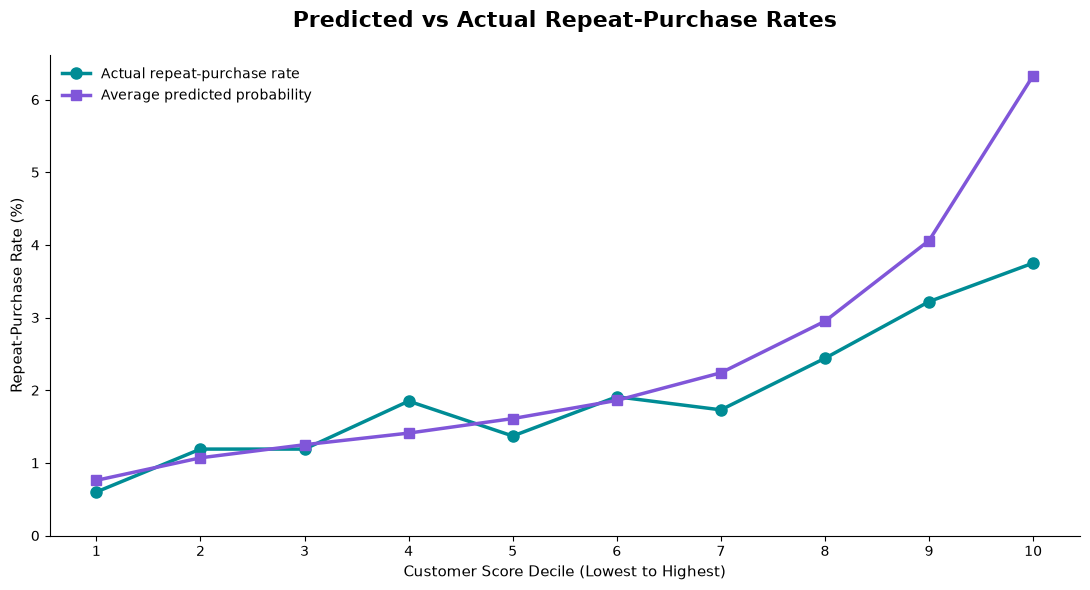

In [158]:
# Step 479: Visualise probability calibration by customer decile

import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(11, 6))

deciles = calibration_summary["score_decile"]

# Plot observed repeat-purchase rates
ax.plot(
    deciles,
    calibration_summary["observed_rate_pct"],
    marker="o",
    linewidth=2.5,
    markersize=8,
    color="#008C95",
    label="Actual repeat-purchase rate"
)

# Plot predicted repeat-purchase rates
ax.plot(
    deciles,
    calibration_summary["predicted_rate_pct"],
    marker="s",
    linewidth=2.5,
    markersize=7,
    color="#8056D9",
    label="Average predicted probability"
)

# Chart formatting
ax.set_title(
    "Predicted vs Actual Repeat-Purchase Rates",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Customer Score Decile (Lowest to Highest)",
    fontsize=11
)

ax.set_ylabel(
    "Repeat-Purchase Rate (%)",
    fontsize=11
)

ax.set_xticks(range(1, 11))
ax.set_ylim(bottom=0)

# Clean professional styling
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(frameon=False, loc="upper left")

plt.tight_layout()
plt.show()

In [159]:
# Step 480: Check probability calibration tools

from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import brier_score_loss, log_loss

print("Probability calibration tools imported successfully!")

print("Scikit-learn version:", sklearn.__version__)

print(
    "Available calibration methods:",
    ["sigmoid", "isotonic"]
)

Probability calibration tools imported successfully!
Scikit-learn version: 1.9.1
Available calibration methods: ['sigmoid', 'isotonic']


In [160]:
# Step 481: Audit possible chronological calibration periods

calibration_timeline = customer_features.loc[
    category_train_mask,
    [
        "order_purchase_timestamp",
        "repeat_purchase_60d"
    ]
].copy()

# Count customers and returners by month
calibration_timeline["purchase_period"] = (
    calibration_timeline["order_purchase_timestamp"]
    .dt.to_period("M")
)

calibration_monthly_summary = (
    calibration_timeline
    .groupby("purchase_period")
    .agg(
        customers=("repeat_purchase_60d", "size"),
        repeat_customers=("repeat_purchase_60d", "sum")
    )
    .reset_index()
)

print("Available training customers:", len(calibration_timeline))

print(
    "Total training repeat purchasers:",
    calibration_timeline["repeat_purchase_60d"].sum()
)

print("\nMonthly training population:")
print(calibration_monthly_summary.to_string(index=False))

Available training customers: 14051
Total training repeat purchasers: 308

Monthly training population:
purchase_period  customers  repeat_customers
        2016-09          3                 0
        2016-10        303                 3
        2016-12          1                 1
        2017-01        742                27
        2017-02       1654                25
        2017-03       2543                51
        2017-04       2275                41
        2017-05       3475                87
        2017-06       3055                73


In [161]:
# Step 482: Audit a leakage-conscious calibration split

calibration_start = pd.Timestamp("2017-05-01")
calibration_end = pd.Timestamp("2017-06-30 23:59:59")

train_dates = customer_features.loc[
    category_train_mask, "order_purchase_timestamp"
]

train_label_ends = (
    train_dates
    + prediction_window
    + delivery_buffer
)

# Earlier customers with labels mature before calibration starts
model_fit_mask = train_label_ends < calibration_start

# Later customers reserved for calibration
calibration_fit_mask = (
    (train_dates >= calibration_start)
    & (train_dates <= calibration_end)
)

# Count customers and positive outcomes
for name, mask in [
    ("Model fitting", model_fit_mask),
    ("Calibration", calibration_fit_mask)
]:
    labels = y_train_category.loc[mask]

    print(f"\n{name}:")
    print("Customers:", len(labels))
    print("Repeat purchasers:", labels.sum())
    print("Repeat-purchase rate:", round(labels.mean() * 100, 2), "%")

print(
    "\nOverlapping customers:",
    (model_fit_mask & calibration_fit_mask).sum()
)

print(
    "Customers outside these periods:",
    (~(model_fit_mask | calibration_fit_mask)).sum()
)


Model fitting:
Customers: 986
Repeat purchasers: 28
Repeat-purchase rate: 2.84 %

Calibration:
Customers: 6530
Repeat purchasers: 160
Repeat-purchase rate: 2.45 %

Overlapping customers: 0
Customers outside these periods: 6535


In [162]:
# Step 483: Audit unused historical months for calibration

unused_calibration_start = pd.Timestamp("2017-07-01")
unused_calibration_end = pd.Timestamp("2017-09-30 23:59:59")

calibration_candidates = customer_features.loc[
    (
        (customer_features["order_purchase_timestamp"]
         >= unused_calibration_start)
        &
        (customer_features["order_purchase_timestamp"]
         <= unused_calibration_end)
    ),
    [
        "order_purchase_timestamp",
        "repeat_purchase_60d",
        "first_order_primary_category"
    ]
].copy()

calibration_candidates["purchase_month"] = (
    calibration_candidates["order_purchase_timestamp"]
    .dt.to_period("M")
)

calibration_month_summary = (
    calibration_candidates
    .groupby("purchase_month")
    .agg(
        customers=("repeat_purchase_60d", "size"),
        repeat_customers=("repeat_purchase_60d", "sum"),
        known_categories=(
            "first_order_primary_category",
            "count"
        )
    )
    .reset_index()
)

print("Potential calibration customers:", len(calibration_candidates))

print("\nMonthly calibration candidates:")
print(calibration_month_summary.to_string(index=False))

print(
    "\nLatest original training label-observation end:",
    label_timeline.loc[
        category_train_mask,
        "label_observation_end"
    ].max()
)

Potential calibration customers: 12203

Monthly calibration candidates:
purchase_month  customers  repeat_customers  known_categories
       2017-07       3893                95              3790
       2017-08       4184               110              4083
       2017-09       4126                99              4030

Latest original training label-observation end: 2017-09-28 23:20:08


In [163]:
# Step 484: Audit the feasible historical calibration window

model_ready_date = (
    label_timeline.loc[
        category_train_mask,
        "label_observation_end"
    ].max()
)

validation_start = pd.Timestamp("2017-10-01")

# Customers purchasing after the original training labels mature
# but before our existing validation period begins

calibration_window_mask = (
    (customer_features["order_purchase_timestamp"] > model_ready_date)
    & (customer_features["order_purchase_timestamp"] < validation_start)
    & category_available
    & basket_available
)

calibration_window = customer_features.loc[
    calibration_window_mask,
    [
        "order_purchase_timestamp",
        "repeat_purchase_60d"
    ]
].copy()

calibration_window["label_observation_end"] = (
    calibration_window["order_purchase_timestamp"]
    + prediction_window
    + delivery_buffer
)

print("Original model labels mature:", model_ready_date)
print("Validation begins:", validation_start)

print("\nPotential calibration customers:", len(calibration_window))

print(
    "Potential calibration repeat purchasers:",
    calibration_window["repeat_purchase_60d"].sum()
)

print(
    "Calibration labels mature before validation:",
    (
        calibration_window["label_observation_end"]
        < validation_start
    ).sum()
)

print(
    "Calibration labels mature after validation begins:",
    (
        calibration_window["label_observation_end"]
        >= validation_start
    ).sum()
)

Original model labels mature: 2017-09-28 23:20:08
Validation begins: 2017-10-01 00:00:00

Potential calibration customers: 219
Potential calibration repeat purchasers: 2
Calibration labels mature before validation: 0
Calibration labels mature after validation begins: 219


## Probability Calibration and Model Reliability

### Objective

Assess whether the repeat-purchase prediction model produces probabilities that accurately reflect observed customer outcomes.

### Weighted vs Unweighted Logistic Regression

Both models used the same nine features and chronological training and validation populations.

| Metric | Weighted Model | Unweighted Model |
|---|---:|---:|
| Average predicted probability | 42.78% | 2.35% |
| Brier score | 0.2143 | 0.0189 |
| Log loss | 0.6170 | 0.0938 |
| Average Precision | 0.0375 | 0.0375 |

The observed validation repeat-purchase rate was 1.93%.

Removing balanced class weights substantially improved probability quality without materially reducing Average Precision.

### Calibration by Customer-Score Decile

The unweighted model's predicted probabilities were reasonably close to observed rates across several lower and middle score deciles.

However, the highest-scoring decile showed notable overestimation:

- Average predicted return probability: 6.33%.
- Observed repeat-purchase rate: 3.75%.
- Difference: 2.58 percentage points.

Therefore, improved overall Brier score and log loss do not establish perfect calibration across customer groups.

### Chronological Calibration Feasibility

A separate calibration dataset was investigated to avoid fitting probability adjustments on the same validation customers used for evaluation.

The latest original training label-observation period ended on 28 September 2017, while validation began on 1 October 2017.

Only 219 potential calibration customers were available between those dates, with two observed repeat purchasers. None had a completed 90-day observation window before validation began.

An earlier chronological training/calibration split also provided insufficient positive cases for reliable classifier training.

### Modelling Decision

No additional sigmoid or isotonic calibration model will be fitted within the current experiment.

The unweighted scaled Logistic Regression model is retained as the current candidate for further reliability testing.

### Remaining Limitations

- Probability estimates remain imperfect, especially among the highest-scoring customers.
- A 90-day observation allowance does not guarantee that every historical order outcome was resolved.
- Historical checkout-time availability of basket and category features has not been fully verified.
- The current category-based modelling population excludes customers with missing primary categories.
- The final test dataset remains untouched.

### Next Steps

Investigate temporal stability across validation months, evaluate the consistency of customer-ranking performance and review feature-availability assumptions before final model selection.

In [164]:
# Step 486: Evaluate model performance across validation months

# Prepare monthly validation results
temporal_validation = pd.DataFrame({
    "purchase_month": customer_features.loc[
        X_validation_category.index,
        "order_purchase_timestamp"
    ].dt.to_period("M").astype(str).to_numpy(),

    "actual_return": y_validation_category.to_numpy(),

    "predicted_probability": unweighted_validation_scores
})

# Evaluate each month separately
monthly_performance = []

for month, group in temporal_validation.groupby("purchase_month"):

    actual = group["actual_return"]
    scores = group["predicted_probability"]

    monthly_performance.append({
        "month": month,
        "customers": len(group),
        "repeat_customers": int(actual.sum()),
        "repeat_rate_pct": round(actual.mean() * 100, 2),
        "average_predicted_pct": round(scores.mean() * 100, 2),
        "average_precision": (
            average_precision_score(actual, scores)
            if actual.nunique() == 2 else np.nan
        ),
        "roc_auc": (
            roc_auc_score(actual, scores)
            if actual.nunique() == 2 else np.nan
        )
    })

monthly_performance = pd.DataFrame(monthly_performance)

# Display results
print("Validation months analysed:", len(monthly_performance))

print("\nMonthly model performance:")
print(
    monthly_performance.round(4).to_string(index=False)
)

print(
    "\nTotal customers:",
    monthly_performance["customers"].sum()
)

print(
    "Total repeat purchasers:",
    monthly_performance["repeat_customers"].sum()
)

Validation months analysed: 3

Monthly model performance:
  month  customers  repeat_customers  repeat_rate_pct  average_predicted_pct  average_precision  roc_auc
2017-10       4353                98             2.25                   2.29             0.0556   0.6642
2017-11       7114               150             2.11                   2.44             0.0384   0.6239
2017-12       5305                75             1.41                   2.28             0.0252   0.5958

Total customers: 16772
Total repeat purchasers: 323


In [165]:
# Step 487: Evaluate monthly Average Precision Lift

monthly_stability = monthly_performance.copy()

# Calculate each month's no-skill AP baseline
monthly_stability["baseline_ap"] = (
    monthly_stability["repeat_customers"]
    / monthly_stability["customers"]
)

# Calculate improvement relative to each month's baseline
monthly_stability["ap_lift"] = (
    monthly_stability["average_precision"]
    / monthly_stability["baseline_ap"]
)

# Compare predicted and observed repeat-purchase rates
monthly_stability["prediction_gap_pp"] = (
    monthly_stability["average_predicted_pct"]
    - monthly_stability["repeat_rate_pct"]
)

print("Monthly ranking and calibration stability:")
print(
    monthly_stability[
        [
            "month",
            "customers",
            "repeat_customers",
            "baseline_ap",
            "average_precision",
            "ap_lift",
            "roc_auc",
            "prediction_gap_pp"
        ]
    ].round(4).to_string(index=False)
)

Monthly ranking and calibration stability:
  month  customers  repeat_customers  baseline_ap  average_precision  ap_lift  roc_auc  prediction_gap_pp
2017-10       4353                98       0.0225             0.0556   2.4676   0.6642               0.04
2017-11       7114               150       0.0211             0.0384   1.8200   0.6239               0.33
2017-12       5305                75       0.0141             0.0252   1.7807   0.5958               0.87


In [166]:
# Step 488: Examine product-category composition across validation months

category_monthly_data = pd.DataFrame({
    "month": customer_features.loc[
        X_validation_category.index,
        "order_purchase_timestamp"
    ].dt.to_period("M").astype(str).to_numpy(),

    "primary_category": X_validation_category[
        "first_order_primary_category"
    ].to_numpy()
})

# Identify the 10 most common categories across validation
top_categories = (
    category_monthly_data["primary_category"]
    .value_counts()
    .head(10)
    .index
)

# Group remaining categories together
category_monthly_data["category_group"] = (
    category_monthly_data["primary_category"]
    .where(
        category_monthly_data["primary_category"].isin(top_categories),
        "Other categories"
    )
)

# Count customers by month and category
monthly_category_counts = pd.crosstab(
    category_monthly_data["month"],
    category_monthly_data["category_group"]
)

# Convert monthly counts into percentages
monthly_category_pct = (
    monthly_category_counts
    .div(monthly_category_counts.sum(axis=1), axis=0)
    .mul(100)
)

print("Customers analysed:", len(category_monthly_data))

print("\nMonthly category composition (%):")
print(
    monthly_category_pct.T
    .round(2)
    .to_string()
)

print("\nMonthly customer totals:")
print(monthly_category_counts.sum(axis=1))

Customers analysed: 16772

Monthly category composition (%):
month                   2017-10  2017-11  2017-12
category_group                                   
Other categories          35.88    33.78    38.28
beleza_saude               7.14     7.25     7.86
brinquedos                 6.23     6.09     7.69
cama_mesa_banho            9.58    10.88     8.43
esporte_lazer              9.26     7.51     7.92
ferramentas_jardim         4.76     5.85     4.47
informatica_acessorios     5.77     6.04     4.52
moveis_decoracao           5.70     7.24     5.50
relogios_presentes         6.43     5.88     6.28
telefonia                  5.08     4.77     4.52
utilidades_domesticas      4.18     4.72     4.52

Monthly customer totals:
month
2017-10    4353
2017-11    7114
2017-12    5305
dtype: int64


In [167]:
# Step 489: Examine repeat-purchase rates within categories by month

category_monthly_retention = pd.DataFrame({
    "month": category_monthly_data["month"].to_numpy(),
    "category_group": category_monthly_data["category_group"].to_numpy(),
    "actual_return": y_validation_category.to_numpy()
})

# Summarise customer counts and return rates
category_monthly_summary = (
    category_monthly_retention
    .groupby(["category_group", "month"])
    .agg(
        customers=("actual_return", "size"),
        repeat_customers=("actual_return", "sum"),
        repeat_rate=("actual_return", "mean")
    )
    .reset_index()
)

category_monthly_summary["repeat_rate_pct"] = (
    category_monthly_summary["repeat_rate"] * 100
)

# Display major categories in a compact format
major_categories = [
    "cama_mesa_banho",
    "esporte_lazer",
    "beleza_saude",
    "brinquedos",
    "moveis_decoracao"
]

major_category_results = category_monthly_summary[
    category_monthly_summary["category_group"].isin(major_categories)
]

print("Customers analysed:", len(category_monthly_retention))

print("\nRepeat-purchase rates by category and month (%):")
print(
    major_category_results.pivot(
        index="category_group",
        columns="month",
        values="repeat_rate_pct"
    ).round(2).to_string()
)

print("\nRepeat purchasers by category and month:")
print(
    major_category_results.pivot(
        index="category_group",
        columns="month",
        values="repeat_customers"
    ).to_string()
)

print("\nCustomer counts by category and month:")
print(
    major_category_results.pivot(
        index="category_group",
        columns="month",
        values="customers"
    ).to_string()
)

Customers analysed: 16772

Repeat-purchase rates by category and month (%):
month             2017-10  2017-11  2017-12
category_group                             
beleza_saude         2.25     2.13     1.44
brinquedos           0.37     1.39     1.72
cama_mesa_banho      6.00     3.36     2.68
esporte_lazer        1.99     4.12     1.67
moveis_decoracao     4.03     2.72     1.37

Repeat purchasers by category and month:
month             2017-10  2017-11  2017-12
category_group                             
beleza_saude            7       11        6
brinquedos              1        6        7
cama_mesa_banho        25       26       12
esporte_lazer           8       22        7
moveis_decoracao       10       14        4

Customer counts by category and month:
month             2017-10  2017-11  2017-12
category_group                             
beleza_saude          311      516      417
brinquedos            271      433      408
cama_mesa_banho       417      774      447
esport

In [172]:
# Restructuring Step 3: Export engineered customer features

from pathlib import Path

# Locate the project's data folder
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

output_dir = project_root / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "customer_features.parquet"

# Save engineered customer features
customer_features.to_parquet(output_path, index=True)

print("Feature dataset saved successfully!")
print("File:", output_path)
print("Customers:", customer_features.shape[0])
print("Columns:", customer_features.shape[1])

ImportError: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - `Import pyarrow` failed. pyarrow is required for parquet support. Use pip or conda to install the pyarrow package.
 - `Import fastparquet` failed. fastparquet is required for parquet support. Use pip or conda to install the fastparquet package.

In [ ]:
# Restructuring Step 3A: Check the current notebook session

print("Current working directory:")

from pathlib import Path
print(Path.cwd())

print("\nIs customer_features available?")
print("customer_features" in globals())

print("\nIs pandas imported?")
print("pd" in globals())

Current working directory:
c:\Users\oades\Downloads\Downloads\customer-intelligence-platform\notebooks

Is customer_features available?
False

Is pandas imported?
False


In [170]:
# Restructuring Step 3E: Verify engineered customer features

print("Dataset available:", "customer_features" in globals())

if "customer_features" in globals():
    print("Dataset shape:", customer_features.shape)
    print("Unique customers:", customer_features["customer_unique_id"].nunique())
    print("Duplicate customer IDs:",
          customer_features["customer_unique_id"].duplicated().sum())
    print("Missing target values:",
          customer_features["repeat_purchase_60d"].isna().sum())

Dataset available: True
Dataset shape: (78100, 29)
Unique customers: 78100
Duplicate customer IDs: 0
Missing target values: 0


In [173]:
# Restructuring Step 3H: Install Parquet support

%pip install pyarrow

   ---------------------------------------- 0.0/29.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/29.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/29.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/29.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/29.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/29.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/29.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/29.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/29.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/29.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/29.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/29.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/29.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/29.2 MB ? eta -:--:--
   -----------------


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [174]:
# Restructuring Step 3I: Export the engineered dataset

from pathlib import Path

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

output_dir = project_root / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "customer_features.parquet"

# Export the customer-level feature dataset
customer_features.to_parquet(output_path, index=True)

# Confirm the file was created
print("Export successful:", output_path.is_file())
print("File location:", output_path)
print("Customers:", customer_features.shape[0])
print("Columns:", customer_features.shape[1])

ImportError: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - The pyarrow installation is not built with support for the Parquet file format (DLL load failed while importing _parquet: An Application Control policy has blocked this file.)
 - `Import fastparquet` failed. fastparquet is required for parquet support. Use pip or conda to install the fastparquet package.

In [175]:
# Restructuring Step 3J: Save engineered features without PyArrow

from pathlib import Path

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

output_dir = project_root / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "customer_features.pkl"

# Save the trusted, locally generated DataFrame
customer_features.to_pickle(output_path)

# Verify the file exists
print("Export successful:", output_path.is_file())
print("File location:", output_path)
print("Customers:", customer_features.shape[0])
print("Columns:", customer_features.shape[1])

Export successful: True
File location: c:\Users\oades\Downloads\Downloads\customer-intelligence-platform\data\processed\customer_features.pkl
Customers: 78100
Columns: 29
